# Main-study results: sensitivity, city correlates, personas, taste discovery

Reads the two zips in `sim_results/` directly (no unzipping needed):

| run | zip | agents | days | conditions |
|---|---|---|---|---|
| **new** | `main_study_recent_2026-10-28.zip` | 2,000 | 100 | 6 (adds PUP+RM) |
| **old** | `main_study_previous_2026-10-14.zip` | 2,500 | 60 | 5 |

Sections
1. **Sensitivity analysis**: old vs new on the 5 shared conditions
2. **Correlates of utility**: (a) city level, census size/density, ACS, street-network metrics, simulation-side city traits; (b) agent level, income, trust, decision paradigm, car access, home distance
3. **Latent class analysis (personas)**: Ng, Mishra & Chen (2025) applied to agents' responses to the recommenders, including their Fig. 3 (information criteria) and Fig. 4 (persona radar grid)
4. **Taste discovery**: taste-match rate by day, recommended vs unaided

Covariates are cached in `.cache/city_covariates/` (gitignored); after the first run nothing is downloaded.
- **Census PEP / Gazetteer**: downloaded once from www2.census.gov (no key).
- **ACS 2019–2023** (income, transit and walk shares, car-free households): read from the welfare Postgres (`WELFARE_RS_PG_DSN`, source `.env.server`), see `city_covariates.acs_postgres`. Off the server, without the DB or the cached CSV, those columns are skipped.
- **Street network**: the simulation's own cached metro graph (`.cache/networks/<city>_metro.graphml`) clipped to the core polygon; Overpass only as a fallback.

In [1]:
import os, sys, zipfile, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

ROOT = Path.cwd()
while not (ROOT / "sim_results").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import city_covariates as cc
from lca import fit_lca

ZIPS = {"new": ROOT / "sim_results" / "main_study_recent_2026-10-28.zip",
        "old": ROOT / "sim_results" / "main_study_previous_2026-10-14.zip"}
LAST_DAY = {"new": 100, "old": 60}
FIG = ROOT / "figs" / "sim_analysis"; FIG.mkdir(parents=True, exist_ok=True)

WITH_NETWORK = True        # OSM network metrics (slow the first time only)
N_CLASSES = 4              # LCA classes used for the persona figures
LCA_STARTS = 10            # random EM starts per K

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

CONDS = ["No RS", "Personalized", "Personalized + PUP", "Personalized + RM",
         "Personalized + PUP+RM", "Oracle"]
SHORT = {"No RS": "No RS", "Personalized": "P", "Personalized + PUP": "P+PUP",
         "Personalized + RM": "P+RM", "Personalized + PUP+RM": "P+PUP+RM", "Oracle": "Oracle"}
CCOL = {"No RS": "#7f7f7f", "Personalized": "#d62728", "Personalized + PUP": "#ff7f0e",
        "Personalized + RM": "#2ca02c", "Personalized + PUP+RM": "#1f77b4", "Oracle": "#9467bd"}
CITY_LABEL = {"nyc": "NYC (Manhattan)", "seattle": "Seattle", "sf_bay": "SF+Oakland",
              "chicago": "Chicago", "houston": "Houston", "dc": "DC", "miami": "Miami", "la": "LA"}

def load(run, name):
    with zipfile.ZipFile(ZIPS[run]) as z:
        files = sorted(f for f in z.namelist() if f.endswith(f"/{name}.csv"))
        return pd.concat([pd.read_csv(z.open(f)) for f in files], ignore_index=True)

res   = {r: load(r, "results") for r in ZIPS}
daily = {r: load(r, "daily")   for r in ZIPS}
agents = {r: load(r, "agents") for r in ZIPS}
SHARED = [c for c in CONDS if c in set(res["old"].condition) & set(res["new"].condition)]
CITIES = sorted(res["new"].city.unique())
for r in ZIPS:
    print(r, {k: len(v[r]) for k, v in [("results", res), ("daily", daily), ("agents", agents)]})
print("shared conditions:", SHARED)

new {'results': 48, 'daily': 24000, 'agents': 480000}
old {'results': 40, 'daily': 12000, 'agents': 500000}
shared conditions: ['No RS', 'Personalized', 'Personalized + PUP', 'Personalized + RM', 'Oracle']


## 1. Sensitivity analysis: old vs new

The two runs differ in **population size** (2,500 vs 2,000), **horizon** (60 vs 100 days), and **model version** (the new run records acceptance, has PUP+RM, and changed the gates). Agents `0..1999` at a given seed are the same people in both runs (same home, income, paradigm, car; see the schema's row-order contract), so the comparison can be paired at agent level.

The checks below:
1. last-day headline metrics side by side, with agreement statistics
2. the recommender effect, ΔU = U(condition) − U(No RS), which is what the paper claims
3. a **horizon-matched** comparison at days 51–60, splitting the total change into a *horizon* part and a *version + population* part
4. condition-ranking stability per city
5. paired agent-level agreement
6. daily trajectories

Table 2 quantities (harmed%, ORC) are **not** compared, because the matched-agent set is defined differently in the two zips.

mean_utility_old                                                          mean_utility_new                                                          d_mean_utility               \
condition            No RS Personalized Personalized + PUP Personalized + RM Oracle            No RS Personalized Personalized + PUP Personalized + RM Oracle          No RS Personalized   
city                                                                                                                                                                                        
chicago              0.170        0.310              0.320             0.321  0.388            0.180        0.253              0.303             0.323  0.382          0.010       -0.057   
dc                   0.130        0.229              0.287             0.277  0.370            0.139        0.209              0.269             0.311  0.371          0.009       -0.020   
houston              0.132        0.256              0.267             0.261  0.333            0.142        0.171              0.273             0.291  0.337          0.010       -0.085   
la                   0.173        0.315              0.312             0.311  0.370            0.184        0.245              0.314             0.327  0.374          0.011       -0.070   
miami                0.244        0.308              0.367             0.361  0.433            0.257        0.307              0.355             0.386  0.436          0.013       -0.001   
nyc                  0.097        0.196              0.235             0.238  0.352            0.106        0.175              0.214             0.276  0.354          0.009       -0.021   
seattle              0.117        0.228              0.276             0.261  0.365            0.121        0.219              0.261             0.294  0.364          0.004       -0.009   
sf_bay               0.123        0.254              0.288             0.282  0.362            0.136        0.213              0.276             0.303  0.374          0.013       -0.041   

                                                       
condition Personalized + PUP Personalized + RM Oracle  
city                                                   
chicago               -0.017             0.003 -0.006  
dc                    -0.019             0.033  0.001  
houston                0.006             0.031  0.004  
la                     0.002             0.016  0.003  
miami                 -0.012             0.025  0.003  
nyc                   -0.021             0.038  0.001  
seattle               -0.015             0.033 -0.001  
sf_bay                -0.012             0.022  0.012

,pearson_r,spearman_rho,CCC,mean_diff(new-old),max_abs_diff
metric,,,,,
mean_utility,0.952,0.929,0.951,-0.002,0.085
neg_rate,0.954,0.908,0.954,0.002,0.074
gini,0.481,0.315,0.445,0.005,0.039
abstention_rate,0.390,0.896,0.382,0.011,0.244


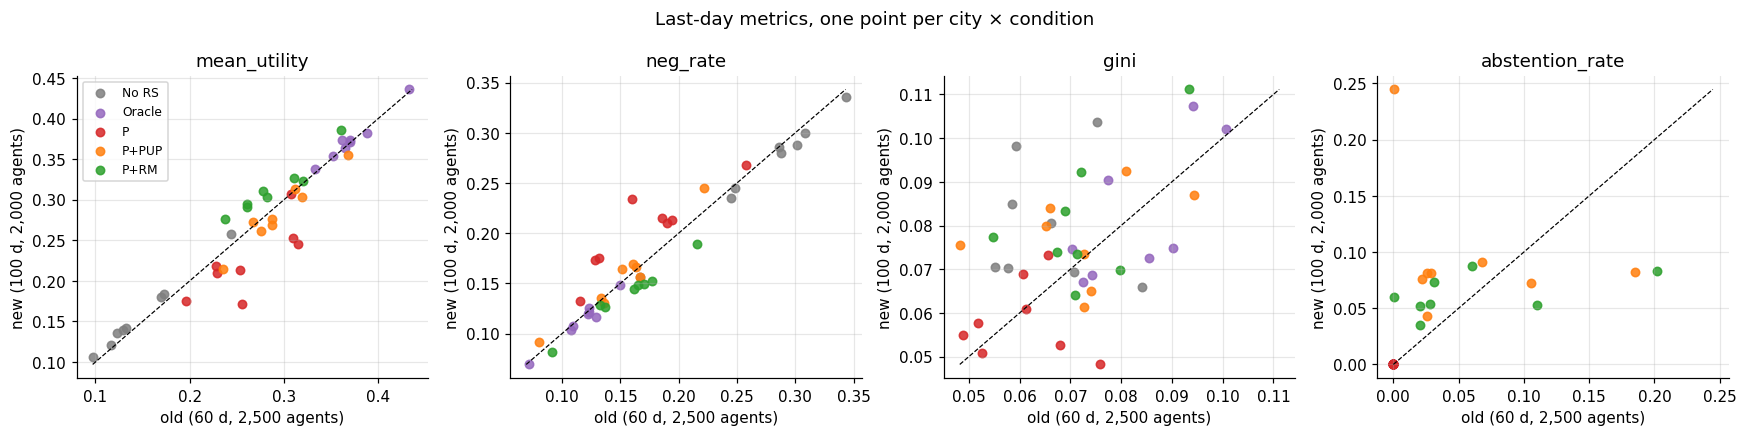

In [2]:
def ccc(x, y):
    'Lin concordance correlation coefficient (agreement, not just correlation).'
    x, y = np.asarray(x, float), np.asarray(y, float)
    sxy = np.cov(x, y, bias=True)[0, 1]
    return 2 * sxy / (x.var() + y.var() + (x.mean() - y.mean()) ** 2)

M = ["mean_utility", "neg_rate", "gini", "abstention_rate"]
cmp = res["new"].merge(res["old"], on=["city", "condition"], suffixes=("_new", "_old"))
for m in M:
    cmp[f"d_{m}"] = cmp[f"{m}_new"] - cmp[f"{m}_old"]

tab = cmp.pivot(index="city", columns="condition", values=["mean_utility_old", "mean_utility_new", "d_mean_utility"])
tab = tab.reindex(columns=SHARED, level=1).round(3)
display(tab)

agree = []
for m in M:
    sub = cmp if m != "abstention_rate" else cmp[cmp.condition != "No RS"]
    x, y = sub[f"{m}_old"], sub[f"{m}_new"]
    agree.append({"metric": m, "pearson_r": stats.pearsonr(x, y)[0], "spearman_rho": stats.spearmanr(x, y)[0],
                  "CCC": ccc(x, y), "mean_diff(new-old)": (y - x).mean(), "max_abs_diff": (y - x).abs().max()})
display(pd.DataFrame(agree).set_index("metric").round(3))

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, m in zip(axs, M):
    sub = cmp if m != "abstention_rate" else cmp[cmp.condition != "No RS"]
    for c, g in sub.groupby("condition"):
        ax.scatter(g[f"{m}_old"], g[f"{m}_new"], s=30, color=CCOL[c], label=SHORT[c], alpha=.85)
    lo = min(sub[f"{m}_old"].min(), sub[f"{m}_new"].min()); hi = max(sub[f"{m}_old"].max(), sub[f"{m}_new"].max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=.8)
    ax.set(title=m, xlabel="old (60 d, 2,500 agents)", ylabel="new (100 d, 2,000 agents)")
axs[0].legend(fontsize=8)
fig.suptitle("Last-day metrics, one point per city × condition"); fig.tight_layout()
fig.savefig(FIG / "sens_scatter_lastday.png", bbox_inches="tight")

### 1.2 Recommender effect ΔU vs No RS (last day)

,ΔU old,ΔU new,change,cities where gain fell
condition,,,,
Personalized,0.114,0.066,-0.048,8
Personalized + PUP,0.146,0.125,-0.021,8
Personalized + RM,0.141,0.156,0.015,1
Oracle,0.223,0.216,-0.008,8


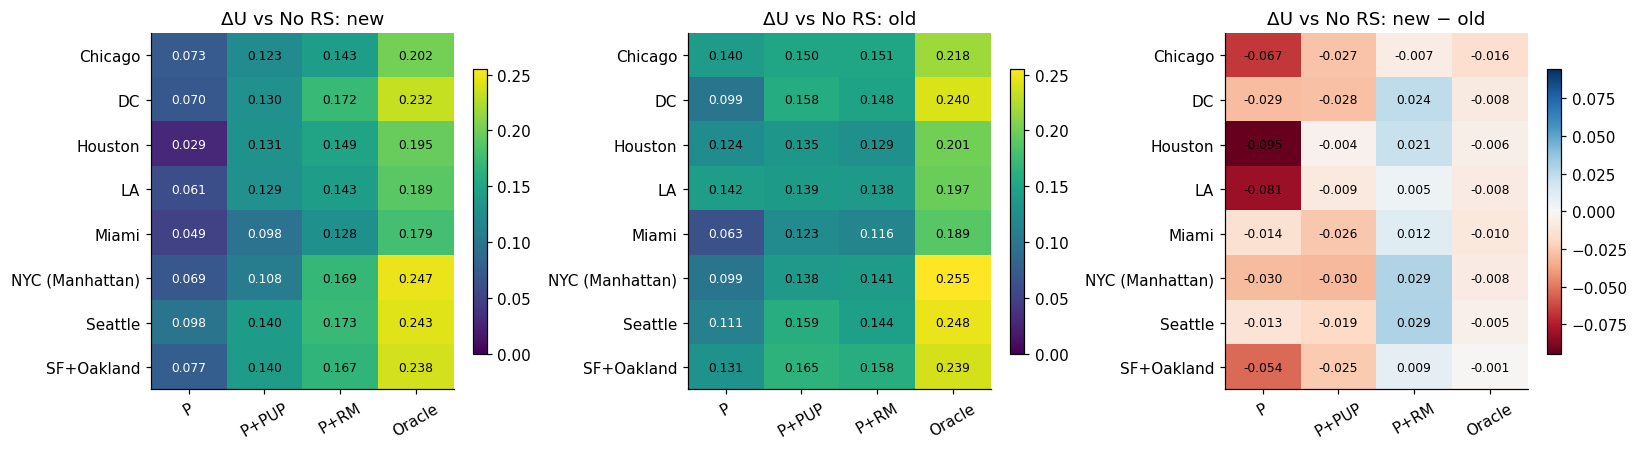

In [3]:
def gains(r):
    p = res[r].pivot(index="city", columns="condition", values="mean_utility")
    return p.sub(p["No RS"], axis=0).drop(columns="No RS")

G = {r: gains(r)[[c for c in SHARED if c != "No RS"]] for r in ZIPS}
G["new − old"] = G["new"] - G["old"]

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (k, g) in zip(axs, G.items()):
    v = np.abs(g.values).max() if k == "new − old" else None
    im = ax.imshow(g.values, cmap="RdBu" if k == "new − old" else "viridis", aspect="auto",
                   vmin=-v if v else 0, vmax=v if v else max(G["new"].values.max(), G["old"].values.max()))
    ax.set_xticks(range(g.shape[1]), [SHORT[c] for c in g.columns], rotation=30)
    ax.set_yticks(range(g.shape[0]), [CITY_LABEL[c] for c in g.index])
    for i, j in itertools.product(range(g.shape[0]), range(g.shape[1])):
        ax.text(j, i, f"{g.values[i, j]:.3f}", ha="center", va="center", fontsize=8,
                color="w" if k != "new − old" and g.values[i, j] < .12 else "k")
    ax.set_title(f"ΔU vs No RS: {k}"); ax.grid(False); plt.colorbar(im, ax=ax, shrink=.8)
fig.tight_layout(); fig.savefig(FIG / "sens_gain_heatmaps.png", bbox_inches="tight")

summary = pd.DataFrame({"ΔU old": G["old"].mean(), "ΔU new": G["new"].mean(),
                        "change": G["new − old"].mean(),
                        "cities where gain fell": (G["new − old"] < 0).sum()}).round(3)
summary

### 1.3 Horizon-matched comparison (days 51–60) and decomposition

The old run stops at day 60, so a last-day comparison mixes *what changed in the model* with *running 40 more days*. Here both runs are averaged over days 51–60, the last 10 days they share, and compared with Welch tests over the 5 seeds (Holm-corrected within each table).
The total change in ΔU splits exactly into:

`new@91–100 − old@51–60 = (new@91–100 − new@51–60) [horizon] + (new@51–60 − old@51–60) [version + population]`

The second term cannot be split further from these two runs: the code version and the population size (2,500 → 2,000; trust quartiles recomputed) changed together. Population size matters here because footfall and popularity feedback depend on how many agents are in the city. Separating them would need a new-code run with 2,500 agents (or an old-code run with 2,000).

Welch tests treat the 5 seeds of each run as independent samples. The same seed draws different random streams in the two runs because the population size differs.

In [4]:
def window(r, d0, d1):
    d = daily[r][(daily[r].day >= d0) & (daily[r].day <= d1)]
    u = d.groupby(["city", "condition", "seed"]).mean_utility.mean().unstack("condition")
    g = u.sub(u["No RS"], axis=0)          # paired within seed: same agents, same draws
    return u, g

u_old, g_old = window("old", 51, 60)
u_new, g_new = window("new", 51, 60)
u_end, g_end = window("new", 91, 100)

def holm(p):
    'Holm step-down adjusted p-values.'
    p = np.asarray(p); m = len(p); o = np.argsort(p)
    out = np.empty(m); out[o] = np.maximum.accumulate((m - np.arange(m)) * p[o]).clip(max=1)
    return out

rows = []
for city in CITIES:
    for c in SHARED:
        a, b = u_old.loc[city, c], u_new.loc[city, c]
        rows.append({"city": city, "condition": c, "metric": "U",
                     "old": a.mean(), "new": b.mean(), "diff": b.mean() - a.mean(),
                     "p": stats.ttest_ind(b, a, equal_var=False).pvalue})
        if c != "No RS":
            a, b = g_old.loc[city, c], g_new.loc[city, c]
            rows.append({"city": city, "condition": c, "metric": "ΔU",
                         "old": a.mean(), "new": b.mean(), "diff": b.mean() - a.mean(),
                         "p": stats.ttest_ind(b, a, equal_var=False).pvalue})
hm = pd.DataFrame(rows)
hm["p_holm"] = hm.groupby("metric").p.transform(holm)
hm["sig"] = np.where(hm.p_holm < .05, "*", "")
display(hm[hm.metric == "ΔU"].pivot(index="city", columns="condition", values="diff")
        .reindex(columns=SHARED[1:]).round(3).astype(str)
        + hm[hm.metric == "ΔU"].pivot(index="city", columns="condition", values="sig").reindex(columns=SHARED[1:]))
print("ΔU(new) − ΔU(old) at days 51–60; * = Holm-adjusted p < .05 over 5 vs 5 seeds")

dec = pd.DataFrame({
    "ΔU old @51–60": g_old.mean(),
    "ΔU new @51–60": g_new.mean(),
    "ΔU new @91–100": g_end.mean()}).drop("No RS")
dec = dec.loc[[c for c in SHARED if c != "No RS"]]
dec["version+population effect"] = dec["ΔU new @51–60"] - dec["ΔU old @51–60"]
dec["horizon effect"] = dec["ΔU new @91–100"] - dec["ΔU new @51–60"]
dec["total"] = dec["version+population effect"] + dec["horizon effect"]
dec.round(4)

condition,Personalized,Personalized + PUP,Personalized + RM,Oracle
city,,,,
chicago,-0.061*,-0.024*,0.0,-0.003
dc,-0.029*,-0.035*,0.013*,-0.004
houston,-0.099*,-0.004,0.016*,-0.004
la,-0.067*,-0.011*,0.007,-0.002
miami,-0.017,-0.021*,0.013*,-0.002
nyc,-0.034*,-0.039*,0.024*,0.0
seattle,-0.028*,-0.025*,0.018*,-0.005
sf_bay,-0.051*,-0.024*,0.009*,-0.004


ΔU(new) − ΔU(old) at days 51–60; * = Holm-adjusted p < .05 over 5 vs 5 seeds


,ΔU old @51–60,ΔU new @51–60,ΔU new @91–100,version+population effect,horizon effect,total
condition,,,,,,
Personalized,0.1122,0.0638,0.0628,-0.0484,-0.0010,-0.0494
Personalized + PUP,0.1450,0.1221,0.1243,-0.0230,0.0022,-0.0208
Personalized + RM,0.1413,0.1538,0.1559,0.0125,0.0021,0.0146
Oracle,0.2199,0.2170,0.2166,-0.0029,-0.0004,-0.0033


### 1.4 Ranking stability and paired agents

,kendall_tau (5 conds),same order of P variants,best (old),"best (new, shared)",order old,order new
city,,,,,,
chicago,1.0,True,P+RM,P+RM,Oracle > P+RM > P+PUP > P > No RS,Oracle > P+RM > P+PUP > P > No RS
dc,0.8,False,P+PUP,P+RM,Oracle > P+PUP > P+RM > P > No RS,Oracle > P+RM > P+PUP > P > No RS
houston,0.8,False,P+PUP,P+RM,Oracle > P+PUP > P+RM > P > No RS,Oracle > P+RM > P+PUP > P > No RS
la,0.4,False,P,P+RM,Oracle > P > P+PUP > P+RM > No RS,Oracle > P+RM > P+PUP > P > No RS
miami,0.8,False,P+PUP,P+RM,Oracle > P+PUP > P+RM > P > No RS,Oracle > P+RM > P+PUP > P > No RS
nyc,1.0,True,P+RM,P+RM,Oracle > P+RM > P+PUP > P > No RS,Oracle > P+RM > P+PUP > P > No RS
seattle,0.8,False,P+PUP,P+RM,Oracle > P+PUP > P+RM > P > No RS,Oracle > P+RM > P+PUP > P > No RS
sf_bay,0.8,False,P+PUP,P+RM,Oracle > P+PUP > P+RM > P > No RS,Oracle > P+RM > P+PUP > P > No RS


paired agent-condition rows: 400,000; trust quartile identical for 94.6% (quartiles are recomputed per population)


,condition,what,spearman,n,sign agreement
0,No RS,avg utility (all days),0.939,78627,NaN
1,Personalized,avg utility (all days),0.879,78669,NaN
2,Personalized,agent gain vs No RS,0.326,78425,0.766
3,Personalized + PUP,avg utility (all days),0.911,78627,NaN
4,Personalized + PUP,agent gain vs No RS,0.452,78391,0.890
5,Personalized + RM,avg utility (all days),0.912,78652,NaN
6,Personalized + RM,agent gain vs No RS,0.497,78406,0.904
7,Oracle,avg utility (all days),0.921,78626,NaN
8,Oracle,agent gain vs No RS,0.644,78396,0.970


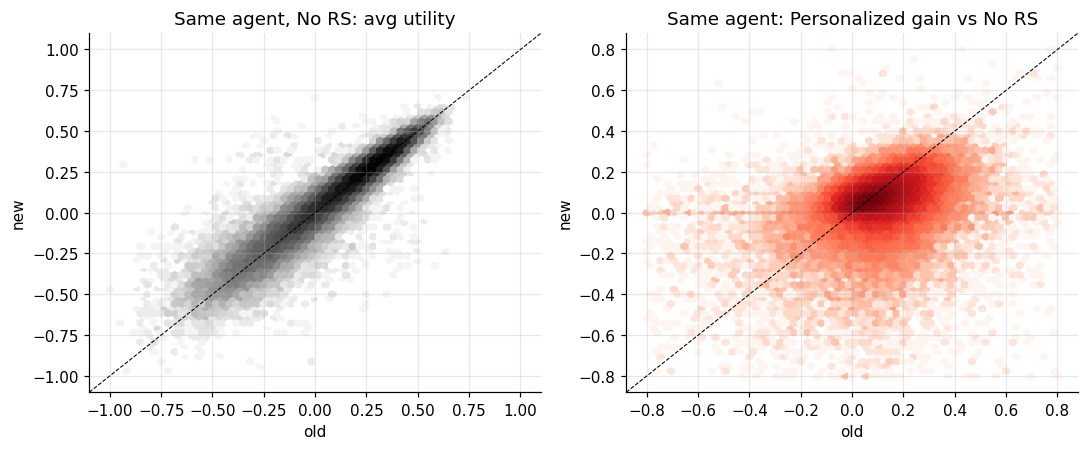

In [5]:
rk = []
for city in CITIES:
    a = res["old"].set_index(["city", "condition"]).loc[city].mean_utility.reindex(SHARED)
    b = res["new"].set_index(["city", "condition"]).loc[city].mean_utility.reindex(SHARED)
    nonor = [c for c in SHARED if c not in ("Oracle", "No RS")]
    v3 = [c for c in SHARED if c.startswith("Personalized")]
    rk.append({"city": city, "kendall_tau (5 conds)": stats.kendalltau(a, b)[0],
               "same order of P variants": list(a[v3].sort_values().index) == list(b[v3].sort_values().index),
               "best (old)": SHORT[a[nonor].idxmax()], "best (new, shared)": SHORT[b[nonor].idxmax()],
               "order old": " > ".join(SHORT[c] for c in a.sort_values(ascending=False).index),
               "order new": " > ".join(SHORT[c] for c in b.sort_values(ascending=False).index)})
display(pd.DataFrame(rk).set_index("city"))

# paired agents: agent_id < 2000 exist in both runs at the same seed
key = ["city", "seed", "agent_id"]
pa = (agents["new"][agents["new"].condition.isin(SHARED)]
      .merge(agents["old"], on=key + ["condition"], suffixes=("_new", "_old")))
print(f"paired agent-condition rows: {len(pa):,}; trust quartile identical for "
      f"{(pa.trust_new == pa.trust_old).mean():.1%} (quartiles are recomputed per population)")
U = {r: pa.pivot_table(index=key, columns="condition", values=f"avg_utility_all_days_{r}") for r in ("new", "old")}
ag = []
for c in SHARED:
    x, y = U["old"][c], U["new"][c]; ok = x.notna() & y.notna()
    ag.append({"condition": c, "what": "avg utility (all days)", "spearman": stats.spearmanr(x[ok], y[ok])[0], "n": ok.sum()})
    if c != "No RS":
        x = U["old"][c] - U["old"]["No RS"]; y = U["new"][c] - U["new"]["No RS"]; ok = x.notna() & y.notna()
        ag.append({"condition": c, "what": "agent gain vs No RS", "spearman": stats.spearmanr(x[ok], y[ok])[0],
                   "n": ok.sum(), "sign agreement": (np.sign(x[ok]) == np.sign(y[ok])).mean()})
display(pd.DataFrame(ag).round(3))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
h = pd.concat({"o": U["old"]["No RS"], "n": U["new"]["No RS"]}, axis=1).dropna()
axs[0].hexbin(h.o, h.n, gridsize=60, bins="log", extent=(-1, 1, -1, 1), cmap="Greys")
axs[0].set(title="Same agent, No RS: avg utility", xlabel="old", ylabel="new")
h = pd.concat({"o": U["old"]["Personalized"] - U["old"]["No RS"],
               "n": U["new"]["Personalized"] - U["new"]["No RS"]}, axis=1).dropna()
axs[1].hexbin(h.o, h.n, gridsize=60, bins="log", extent=(-.8, .8, -.8, .8), cmap="Reds")
axs[1].set(title="Same agent: Personalized gain vs No RS", xlabel="old", ylabel="new")
for ax in axs: ax.axline((0, 0), slope=1, color="k", lw=.7, ls="--")
fig.tight_layout(); fig.savefig(FIG / "sens_paired_agents.png", bbox_inches="tight")

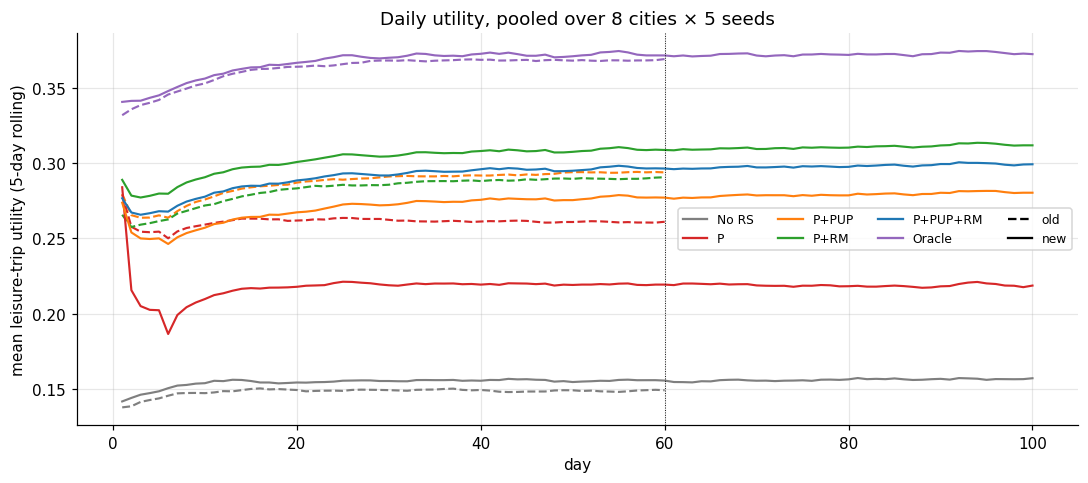

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for r, ls in [("old", "--"), ("new", "-")]:
    d = daily[r].groupby(["condition", "day"]).mean_utility.mean().unstack(0)
    for c in d.columns:
        ax.plot(d.index, d[c].rolling(5, min_periods=1).mean(), ls=ls, color=CCOL[c], lw=1.4)
ax.axvline(60, color="k", lw=.6, ls=":")
ax.legend(handles=[Line2D([], [], color=CCOL[c], label=SHORT[c]) for c in CONDS] +
          [Line2D([], [], color="k", ls="--", label="old"), Line2D([], [], color="k", ls="-", label="new")],
          ncol=4, fontsize=8)
ax.set(xlabel="day", ylabel="mean leisure-trip utility (5-day rolling)", title="Daily utility, pooled over 8 cities × 5 seeds")
fig.tight_layout(); fig.savefig(FIG / "sens_daily_trajectories.png", bbox_inches="tight")

## 2. Correlates of utility
### 2a. City level

**Unit of analysis: the 8 principal cities.** With n = 8, Spearman ρ must exceed about ±0.74 to reach p < .05. P-values are **exact permutation p** (all 8! orderings). The analysis is exploratory: covariates are collinear (density ↔ intersection density ↔ transit), and nothing here is causal.

**Multiple comparisons:** the heatmap runs ~20 covariates × 7 outcomes ≈ 140 tests, so about 7 reach p < .05 by chance alone. The cell below prints the observed count against that expectation and a Benjamini–Hochberg count. Treat single starred cells as hypotheses.
**Mechanical covariates:** `car_share` and `home_km_median` describe the *simulated population*, not the city itself. A correlation with them can be a composition effect (for example, car-free agents have more Oracle headroom) rather than a property of urban form.

To guard against seed noise, each ρ is also recomputed per seed (5 values), and checked in both runs. A correlate worth reporting should hold its sign across seeds and across old/new.

**Covariates**
- *Census*: population (PEP 2023), land area (Gazetteer), density, 2020–23 growth
- *ACS 2019–2023 5-year* (welfare Postgres): median household income, transit and walk commute shares (of all workers 16+, incl. work-from-home), zero-vehicle household share. Manhattan and San Francisco are exact county figures. The other cities are built from 2020 block groups apportioned to the city by 2020 housing units (household tables) or population (commute table), with block → place from the Census 2020 Block Assignment Files. At most 7% of a city's population (Houston) lives in block groups split by the city boundary. Income is a **linear interpolation of the B19001 bins**: it approximates, but is not, the published B19013 median, which does not matter for rank correlations.
- *Network (OSM drive graph of the core: the simulation's metro graph clipped to the core polygon; densities per Census **land** km², because the OSM polygons include water)*: intersection density, street density, mean segment length, circuity, streets per node, 4-way and dead-end shares, orientation entropy (grid-ness: low = gridded)
- *Simulation-side*: POI catalog size and density, median home-to-downtown distance of agents (commute-shed spread), agents' car-ownership share

In [7]:
cov = cc.all_covariates(with_network=WITH_NETWORK)

DOWNTOWN = {"nyc": (40.7128, -74.0060), "seattle": (47.6036, -122.3294), "sf_bay": (37.7793, -122.4193),
            "chicago": (41.8837, -87.6319), "houston": (29.7604, -95.3698), "dc": (38.8951, -77.0364),
            "miami": (25.7743, -80.1937), "la": (34.0537, -118.2428)}
# approximate downtown reference points (CBD / civic centre; Miami = downtown, not Dinner Key city hall;
# SF+Oakland measured from SF Civic Center). Used only for the commute-shed spread covariate.
def hav_km(lat, lon, lat0, lon0):
    p = np.pi / 180
    a = np.sin((lat - lat0) * p / 2) ** 2 + np.cos(lat * p) * np.cos(lat0 * p) * np.sin((lon - lon0) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))

a0 = agents["new"][agents["new"].condition == "No RS"].copy()
a0["home_km"] = [hav_km(la, lo, *DOWNTOWN[c]) for c, la, lo in zip(a0.city, a0.home_lat, a0.home_lon)]
sim_cov = pd.DataFrame({
    "n_places": daily["new"].groupby("city").n_places.first(),
    "home_km_median": a0.groupby("city").home_km.median(),
    "car_share": a0.groupby("city").car_access.apply(lambda s: (s == "own car").mean()),
})
cov = cov.join(sim_cov)
cov["poi_per_km2"] = cov.n_places / cov.land_km2
cov = cov.dropna(axis=1, how="all")
cov.T.round(3)

network source: {'nyc': 'sim metro graph clipped to core', 'seattle': 'sim metro graph clipped to core', 'sf_bay': 'sim metro graph clipped to core', 'chicago': 'sim metro graph clipped to core', 'houston': 'sim metro graph clipped to core', 'dc': 'sim metro graph clipped to core', 'miami': 'sim metro graph clipped to core', 'la': 'sim metro graph clipped to core'}


city,nyc,seattle,sf_bay,chicago,houston,dc,miami,la
pop_2020,1694250.000,737018.000,1314619.000,2746352.000,2300833.000,689548.000,442260.000,3898841.000
pop_2023,1597451.000,755078.000,1245492.000,2664452.000,2314157.000,678972.000,455924.000,3820914.000
land_km2,58.684,217.559,265.896,589.865,1659.162,158.316,93.229,1218.633
density_per_km2,27221.260,3470.682,4684.133,4517.057,1394.775,4288.724,4890.356,3135.409
pop_growth_20_23,-0.057,0.025,-0.053,-0.030,0.006,-0.015,0.031,-0.020
med_hh_income_interp,104972.745,121632.569,123203.121,75146.773,64175.005,107213.541,59220.029,80655.758
transit_commute_share,0.455,0.139,0.192,0.193,0.032,0.223,0.070,0.067
walk_commute_share,0.186,0.083,0.077,0.057,0.019,0.100,0.054,0.031
zero_vehicle_hh_share,0.777,0.189,0.252,0.267,0.095,0.359,0.176,0.118
osm_area_km2,87.274,373.119,804.923,606.781,1589.455,177.208,143.110,1361.343


,U_NoRS,U_Personalized,ΔU_Oracle,ΔU_P,ΔU_P+PUP,ΔU_P+PUP+RM,ΔU_P+RM,P_share_of_oracle_gain,neg_rate_NoRS,harmed_pct_P
city,,,,,,,,,,
chicago,0.180,0.253,0.202,0.073,0.123,0.134,0.143,0.361,0.235,0.261
dc,0.139,0.209,0.232,0.070,0.130,0.161,0.172,0.302,0.286,0.331
houston,0.142,0.171,0.195,0.029,0.131,0.140,0.149,0.149,0.280,0.292
la,0.184,0.245,0.189,0.061,0.129,0.136,0.143,0.321,0.245,0.247
miami,0.257,0.307,0.179,0.049,0.098,0.125,0.128,0.276,0.157,0.326
nyc,0.106,0.175,0.247,0.069,0.108,0.130,0.169,0.279,0.335,0.307
seattle,0.121,0.219,0.243,0.098,0.140,0.162,0.173,0.404,0.300,0.291
sf_bay,0.136,0.213,0.238,0.077,0.140,0.161,0.167,0.323,0.288,0.288


new: 8 of 140 cells p<.05 (≈7 expected under the null); BH-FDR q<.10: 0
old: 21 of 140 cells p<.05 (≈7 expected under the null); BH-FDR q<.10: 0


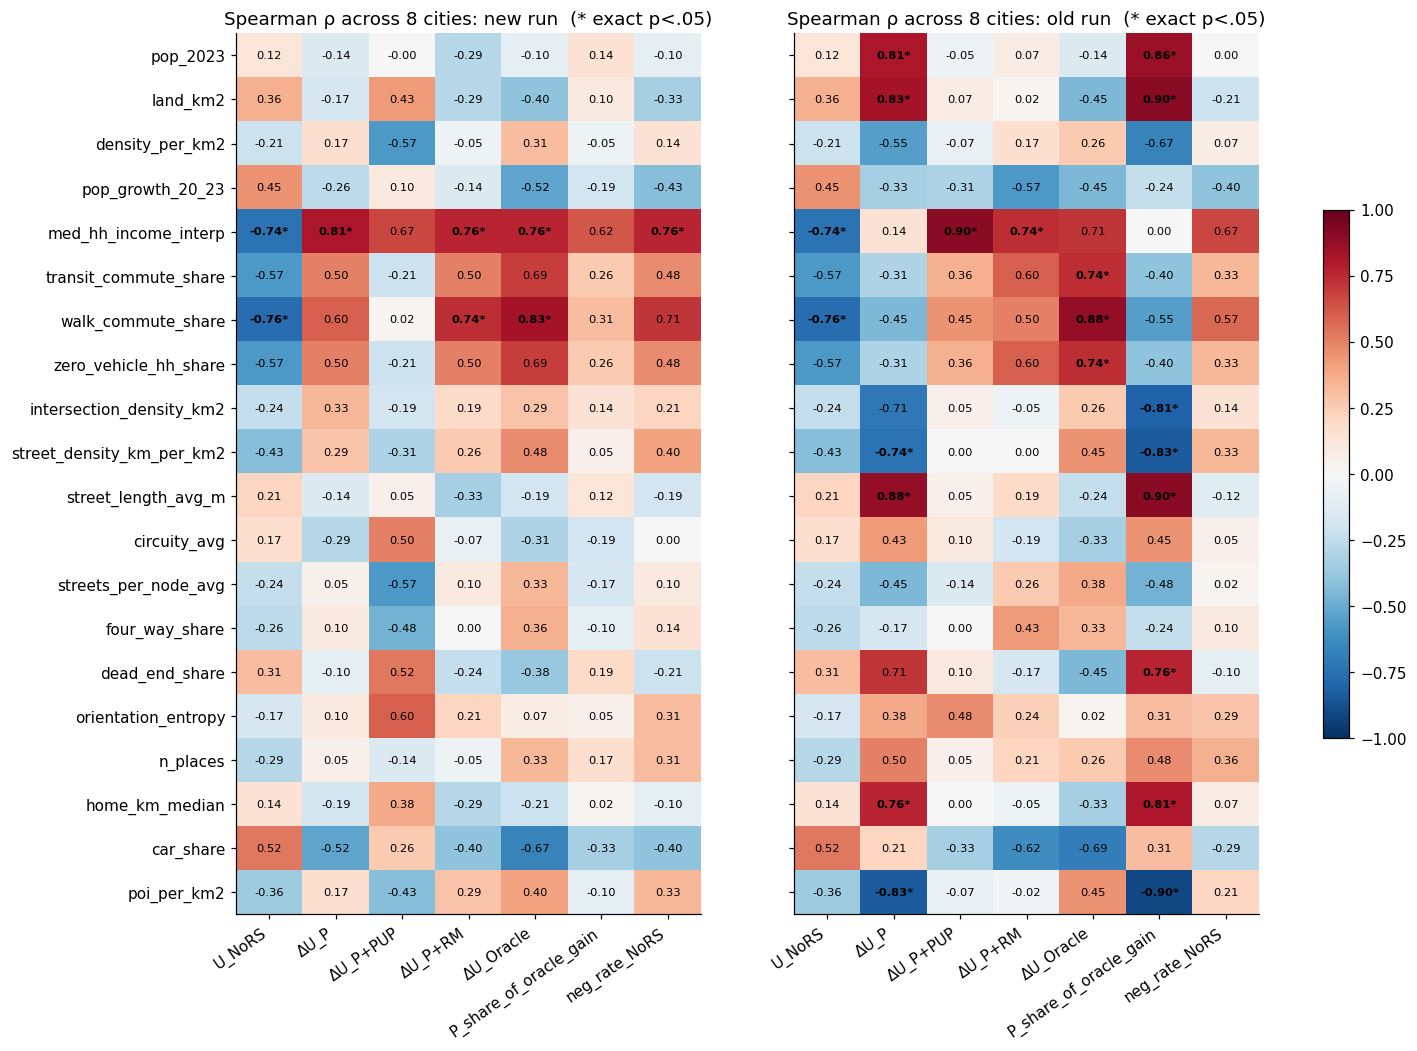

In [8]:
def city_outcomes(r):
    t = res[r].set_index(["city", "condition"])
    U = t.mean_utility.unstack()
    o = pd.DataFrame({"U_NoRS": U["No RS"], "U_Personalized": U["Personalized"]})
    for c in U.columns.drop("No RS"):
        o[f"ΔU_{SHORT[c]}"] = U[c] - U["No RS"]
    o["P_share_of_oracle_gain"] = o["ΔU_P"] / o["ΔU_Oracle"]
    o["neg_rate_NoRS"] = t.neg_rate.unstack()["No RS"]
    o["harmed_pct_P"] = t.harmed_pct.unstack()["Personalized"]   # within-run only
    return o

OUT = {r: city_outcomes(r) for r in ZIPS}
display(OUT["new"].round(3))

COVS = [c for c in cov.columns if c not in ("pop_2020", "net_nodes", "net_edges", "osm_area_km2")]
OUTS = ["U_NoRS", "ΔU_P", "ΔU_P+PUP", "ΔU_P+RM", "ΔU_Oracle", "P_share_of_oracle_gain", "neg_rate_NoRS"]

PERMS = np.array(list(itertools.permutations(range(len(CITIES)))))
def spearman_exact(x, y):
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    rx, ry = (rx - rx.mean()) / rx.std(), (ry - ry.mean()) / ry.std()
    rho = (rx * ry).mean()
    null = (ry[PERMS] * rx).mean(1)
    return rho, (np.abs(null) >= abs(rho) - 1e-12).mean()

def corr_table(out, covs=COVS, outs=OUTS):
    R = pd.DataFrame(index=covs, columns=outs, dtype=float); P = R.copy()
    for a in covs:
        for b in outs:
            x = cov.loc[CITIES, a].values; y = out.loc[CITIES, b].values
            R.loc[a, b], P.loc[a, b] = spearman_exact(x, y)
    return R, P

CORR = {r: corr_table(OUT[r]) for r in ZIPS}
from statsmodels.stats.multitest import multipletests
for r in ZIPS:
    p = CORR[r][1].values.ravel()
    print(f"{r}: {(p < .05).sum()} of {p.size} cells p<.05 (≈{.05 * p.size:.0f} expected under the null); "
          f"BH-FDR q<.10: {multipletests(p, alpha=.10, method='fdr_bh')[0].sum()}")

fig, axs = plt.subplots(1, 2, figsize=(15, 0.42 * len(COVS) + 2), sharey=True)
for ax, r in zip(axs, ["new", "old"]):
    R, P = CORR[r]
    im = ax.imshow(R.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    for i, j in itertools.product(*map(range, R.shape)):
        ax.text(j, i, f"{R.values[i, j]:.2f}" + ("*" if P.values[i, j] < .05 else ""), ha="center", va="center",
                fontsize=7.5, fontweight="bold" if P.values[i, j] < .05 else "normal")
    ax.set_xticks(range(len(OUTS)), OUTS, rotation=35, ha="right"); ax.set_yticks(range(len(COVS)), COVS)
    ax.set_title(f"Spearman ρ across 8 cities: {r} run  (* exact p<.05)"); ax.grid(False)
plt.colorbar(im, ax=axs, shrink=.6)
fig.savefig(FIG / "city_corr_heatmap.png", bbox_inches="tight")

In [9]:
# Per-seed robustness: recompute ρ with each seed's last-10-day city utilities
def seed_outcomes(r):
    d0 = LAST_DAY[r] - 9
    d = daily[r][daily[r].day >= d0].groupby(["seed", "city", "condition"]).mean_utility.mean().unstack()
    o = pd.DataFrame({"U_NoRS": d["No RS"], "ΔU_P": d["Personalized"] - d["No RS"],
                      "ΔU_P+RM": d["Personalized + RM"] - d["No RS"], "ΔU_Oracle": d["Oracle"] - d["No RS"]})
    return o

rob = []
for r in ZIPS:
    so = seed_outcomes(r)
    for b in so.columns:
        for a in COVS:
            rhos = [spearman_exact(cov.loc[CITIES, a].values, so.loc[s].loc[CITIES, b].values)[0]
                    for s in so.index.get_level_values(0).unique()]
            rob.append({"run": r, "outcome": b, "covariate": a, "rho_mean": np.mean(rhos),
                        "rho_min": np.min(rhos), "rho_max": np.max(rhos),
                        "same_sign_all_seeds": np.all(np.sign(rhos) == np.sign(np.mean(rhos)))})
rob = pd.DataFrame(rob)
wide = rob.pivot_table(index=["outcome", "covariate"], columns="run", values=["rho_mean", "rho_min", "rho_max"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
stable = rob.groupby(["outcome", "covariate"]).same_sign_all_seeds.all()
wide["stable (all seeds, both runs)"] = stable
wide["agree_sign_runs"] = np.sign(wide.rho_mean_new) == np.sign(wide.rho_mean_old)
robust = wide[wide["stable (all seeds, both runs)"] & wide.agree_sign_runs &
              (wide[["rho_mean_new", "rho_mean_old"]].abs().min(axis=1) >= .6)]
print("Correlates with |ρ| ≥ 0.6 in both runs and the same sign in every seed of both runs:")
robust.sort_values("rho_mean_new", key=np.abs, ascending=False).round(2)

Correlates with |ρ| ≥ 0.6 in both runs and the same sign in every seed of both runs:


rho_max_new  rho_max_old  rho_mean_new  rho_mean_old  rho_min_new  rho_min_old  stable (all seeds, both runs)  agree_sign_runs
outcome   covariate                                                                                                                                            
ΔU_Oracle walk_commute_share            0.90         0.90          0.89          0.86         0.86         0.81                           True             True
ΔU_P+RM   med_hh_income_interp          0.93         0.90          0.85          0.78         0.74         0.71                           True             True
ΔU_Oracle med_hh_income_interp          0.81         0.86          0.78          0.78         0.76         0.71                           True             True
U_NoRS    walk_commute_share           -0.71        -0.71         -0.77         -0.78        -0.81        -0.83                           True             True
ΔU_Oracle transit_commute_share         0.86         0.76          0.76          0.70         0.71         0.62                           True             True
          zero_vehicle_hh_share         0.86         0.76          0.76          0.70         0.71         0.62                           True             True
          car_share                    -0.69        -0.60         -0.72         -0.67        -0.79        -0.71                           True             True
U_NoRS    med_hh_income_interp         -0.69        -0.67         -0.71         -0.72        -0.76        -0.76                           True             True
ΔU_P+RM   transit_commute_share         0.83         0.71          0.63          0.61         0.48         0.45                           True             True
          zero_vehicle_hh_share         0.83         0.71          0.63          0.61         0.48         0.45                           True             True

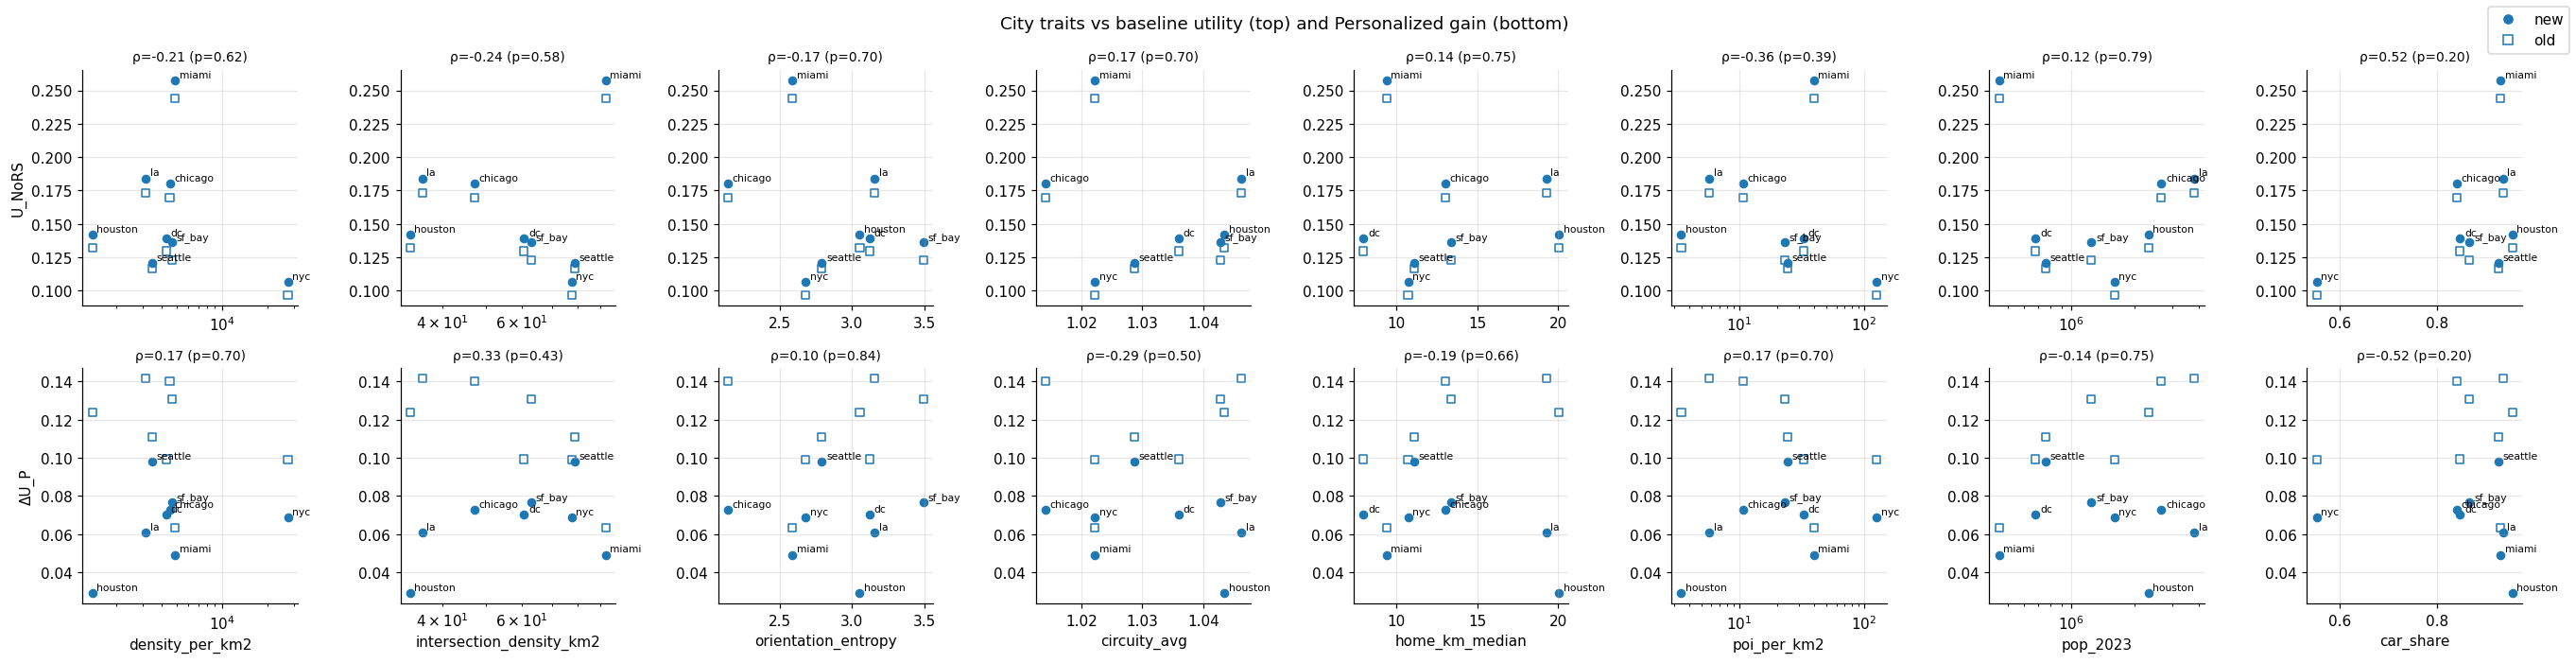

In [10]:
SHOW = [c for c in ["density_per_km2", "intersection_density_km2", "orientation_entropy", "circuity_avg",
                    "home_km_median", "poi_per_km2", "pop_2023", "car_share"] if c in cov.columns]
fig, axs = plt.subplots(2, len(SHOW), figsize=(3.1 * len(SHOW), 6.4))
for j, a in enumerate(SHOW):
    for i, b in enumerate(["U_NoRS", "ΔU_P"]):
        ax = axs[i, j]
        for r, mk in [("new", "o"), ("old", "s")]:
            ax.scatter(cov.loc[CITIES, a], OUT[r].loc[CITIES, b], marker=mk, s=28,
                       facecolor="C0" if r == "new" else "none", edgecolor="C0")
        for c in CITIES:
            ax.annotate(c, (cov.loc[c, a], OUT["new"].loc[c, b]), fontsize=7, xytext=(3, 2), textcoords="offset points")
        rho, p = CORR["new"][0].loc[a, b], CORR["new"][1].loc[a, b]
        ax.set_title(f"ρ={rho:.2f} (p={p:.2f})", fontsize=9)
        if a in ("density_per_km2", "pop_2023", "poi_per_km2", "intersection_density_km2"): ax.set_xscale("log")
        ax.set_xlabel(a if i == 1 else ""); ax.set_ylabel(b if j == 0 else "")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color="C0", label="new"),
                    Line2D([], [], marker="s", ls="", mfc="none", color="C0", label="old")], loc="upper right")
fig.suptitle("City traits vs baseline utility (top) and Personalized gain (bottom)"); fig.tight_layout()
fig.savefig(FIG / "city_scatter_grid.png", bbox_inches="tight")

### 2b. Agent level

**Unit:** agent × seed, using the agent's utility averaged over all days (new: 100, old: 60). Outcomes are the No-RS baseline and each recommender's gain over No RS for the same agent and seed.
**Model:** OLS of each outcome on agent traits with **city × seed fixed effects**, so every coefficient compares agents within the same simulated environment. SEs are cluster-robust by city × seed (40 clusters). Reported as coefficient, then stars: * p<.05, ** p<.01, *** p<.001.

Notes for reading these:
- Traits are set before the simulation, so the shared-baseline regression to the mean that affects the LCA gains does **not** bias these coefficients (noise in U(No RS) is independent of the traits).
- Coefficients are **associations among traits that co-occur in the synthetic population**, not causal effects of a trait. Trust is a built-in placebo: it cannot act under No RS, yet trust Q2 has a small non-zero No-RS coefficient, so trust quartiles carry some other agent differences not in the model.
- With n ≈ 79k–99k almost everything is "significant". Read the size of the effect and the within-R² (share of within-environment variance explained by the traits).
- Income is harmonized to 3 bands across the two label sets. The coarse source's `35-75k` band is put in $50–100k and `<35k` in <$50k, so the middle band is approximate at the edges.
- **Sensitivity:** the same model is fit on the old run (60 days, 2,500 agents). A coefficient that keeps its sign and rough size across runs is robust to the version + population change.

In [11]:
import statsmodels.formula.api as smf

INC = {"Under $25,000": "<$50k", "$25,000 - $49,999": "<$50k", "<35k": "<$50k",
       "$50,000 - $74,999": "$50–100k", "$75,000 - $99,999": "$50–100k", "35-75k": "$50–100k",
       "$100,000 - $149,000": "$100k+", "$150,000 - $199,999": "$100k+", "$200,000 or more": "$100k+", "125k+": "$100k+"}
OUTCOME_CONDS = {"U_NoRS": None, "ΔU_P": "Personalized", "ΔU_P+PUP": "Personalized + PUP",
                 "ΔU_P+RM": "Personalized + RM", "ΔU_P+PUP+RM": "Personalized + PUP+RM", "ΔU_Oracle": "Oracle"}
key = ["city", "seed", "agent_id"]

def agent_frame(r, paired=False):
    a = agents[r] if not paired else agents[r][agents[r].agent_id < 2000]
    u = a.pivot_table(index=key, columns="condition", values="avg_utility_all_days")
    f = a[a.condition == "No RS"].set_index(key)[["income", "trust", "paradigm", "car_access", "home_lat", "home_lon"]]
    f = f.reindex(u.index)
    f["U_NoRS"] = u["No RS"]
    for o, c in OUTCOME_CONDS.items():
        if c is not None and c in u.columns:
            f[o] = u[c] - u["No RS"]
    f["income3"] = f.income.map(INC)
    assert f.income3.notna().all(), f.income[f.income3.isna()].unique()
    f = f.reset_index()
    f["home_km"] = [hav_km(la, lo, *DOWNTOWN[c]) for c, la, lo in zip(f.city, f.home_lat, f.home_lon)]
    f["log_home_km"] = np.log1p(f.home_km)
    f["no_car"] = (f.car_access == "none").astype(int)
    f["cs"] = f.city + "_" + f.seed.astype(str)          # city × seed environment
    return f.dropna(subset=["U_NoRS"])

AF = {r: agent_frame(r) for r in ZIPS}
AFp = {r: agent_frame(r, paired=True) for r in ZIPS}
print({r: len(v) for r, v in AF.items()}, "agent × seed rows with ≥1 leisure trip")

{'new': 79051, 'old': 98503} agent × seed rows with ≥1 leisure trip


In [12]:
def gap_table(f, by):
    outs = [o for o in OUTCOME_CONDS if o in f.columns]
    return f.groupby(by)[outs].mean()

# Raw group means on the paired agents (agent_id < 2000, same people in both runs); no controls
for v in ["car_access", "income3", "trust", "paradigm"]:
    t = pd.concat({r: gap_table(AFp[r], v) for r in ("old", "new")}, axis=1)
    t[("", "n (new)")] = AFp["new"].groupby(v).size()
    display(t.round(3))

old                                      new                                                      
           U_NoRS   ΔU_P ΔU_P+PUP ΔU_P+RM ΔU_Oracle U_NoRS   ΔU_P ΔU_P+PUP ΔU_P+RM ΔU_P+PUP+RM ΔU_Oracle n (new)
car_access                                                                                                      
none       -0.033  0.061    0.119   0.133     0.252 -0.028 -0.047    0.065   0.149       0.081     0.247   10893
own car     0.130  0.109    0.135   0.130     0.210  0.138  0.055    0.117   0.143       0.138     0.208   68158

old                                      new                                                      
         U_NoRS   ΔU_P ΔU_P+PUP ΔU_P+RM ΔU_Oracle U_NoRS   ΔU_P ΔU_P+PUP ΔU_P+RM ΔU_P+PUP+RM ΔU_Oracle n (new)
income3                                                                                                       
$100k+   -0.022  0.102    0.143   0.145     0.248 -0.015  0.035    0.115   0.160       0.146     0.246   40445
$50–100k  0.209  0.108    0.128   0.122     0.192  0.217  0.056    0.107   0.137       0.122     0.190   21896
<$50k     0.288  0.097    0.113   0.108     0.167  0.295  0.038    0.098   0.115       0.101     0.164   16710

old                                      new                                                      
      U_NoRS   ΔU_P ΔU_P+PUP ΔU_P+RM ΔU_Oracle U_NoRS   ΔU_P ΔU_P+PUP ΔU_P+RM ΔU_P+PUP+RM ΔU_Oracle n (new)
trust                                                                                                      
Q1     0.117  0.083    0.107   0.103     0.170  0.126  0.033    0.086   0.114       0.103     0.168   19772
Q2     0.095  0.096    0.123   0.123     0.200  0.102  0.037    0.100   0.133       0.118     0.198   19730
Q3     0.119  0.114    0.144   0.143     0.232  0.120  0.048    0.118   0.154       0.138     0.226   19791
Q4     0.101  0.121    0.159   0.158     0.266  0.110  0.047    0.133   0.176       0.159     0.261   19758

old                                      new                                                      
            U_NoRS   ΔU_P ΔU_P+PUP ΔU_P+RM ΔU_Oracle U_NoRS   ΔU_P ΔU_P+PUP ΔU_P+RM ΔU_P+PUP+RM ΔU_Oracle n (new)
paradigm                                                                                                         
habit        0.115  0.095    0.124   0.123     0.205  0.122  0.034    0.104   0.137       0.125     0.204   16056
prospect     0.131  0.103    0.131   0.129     0.215  0.137  0.044    0.115   0.144       0.134     0.214   15245
regret       0.095  0.108    0.141   0.138     0.224  0.103  0.046    0.113   0.150       0.133     0.220   15598
satisficing  0.114  0.098    0.126   0.123     0.208  0.120  0.036    0.103   0.138       0.123     0.206   17945
utility      0.083  0.111    0.144   0.142     0.228  0.089  0.048    0.114   0.154       0.135     0.226   14207

outcome,U_NoRS,ΔU_P,ΔU_P+PUP,ΔU_P+RM,ΔU_P+PUP+RM,ΔU_Oracle
income $50–100k (vs $100k+),+0.246***,+0.034***,-0.003,-0.021***,-0.017***,-0.054***
income <$50k (vs $100k+),+0.347***,+0.026***,-0.008**,-0.045***,-0.035***,-0.085***
trust Q1 (vs Q4),-0.001,-0.015***,-0.046***,-0.059***,-0.054***,-0.089***
trust Q2 (vs Q4),-0.020***,-0.007**,-0.032***,-0.040***,-0.037***,-0.060***
trust Q3 (vs Q4),-0.001,+0.002,-0.014***,-0.020***,-0.019***,-0.033***
habit (vs utility),+0.028***,-0.014***,-0.009***,-0.015***,-0.009***,-0.019***
prospect (vs utility),+0.047***,-0.003,+0.002,-0.009***,-0.000,-0.012***
regret (vs utility),+0.014***,-0.001,-0.001,-0.004**,-0.002,-0.006***
satisficing (vs utility),+0.023***,-0.012***,-0.011***,-0.015***,-0.011***,-0.018***
no car,-0.243***,-0.111***,-0.047***,+0.012***,-0.051***,+0.043***


outcome,U_NoRS,ΔU_P,ΔU_P+PUP,ΔU_P+RM,ΔU_Oracle
income $50–100k (vs $100k+),+0.243***,+0.010*,-0.012***,-0.020***,-0.054***
income <$50k (vs $100k+),+0.348***,+0.005,-0.027***,-0.037***,-0.085***
trust Q1 (vs Q4),-0.004*,-0.040***,-0.052***,-0.052***,-0.092***
trust Q2 (vs Q4),-0.023***,-0.024***,-0.034***,-0.032***,-0.061***
trust Q3 (vs Q4),-0.002,-0.009***,-0.016***,-0.015***,-0.033***
habit (vs utility),+0.029***,-0.015***,-0.019***,-0.018***,-0.020***
prospect (vs utility),+0.048***,-0.008***,-0.013***,-0.013***,-0.012***
regret (vs utility),+0.014***,-0.002,-0.003*,-0.004**,-0.004***
satisficing (vs utility),+0.024***,-0.013***,-0.018***,-0.018***,-0.017***
no car,-0.239***,-0.043***,-0.011**,+0.003,+0.046***


old                                           new                                                      
           U_NoRS           ΔU_P         ΔU_P+RM         U_NoRS           ΔU_P         ΔU_P+RM         car-free share
car_access   none own car   none own car    none own car   none own car   none own car    none own car               
city                                                                                                                 
chicago     0.003   0.161  0.086   0.127   0.139   0.136  0.010   0.169 -0.030   0.072   0.145   0.142          0.158
dc         -0.018   0.095  0.053   0.092   0.151   0.146 -0.014   0.102 -0.070   0.056   0.178   0.158          0.148
houston    -0.129   0.119  0.089   0.122   0.109   0.112 -0.121   0.126 -0.057   0.021   0.103   0.136          0.044
la         -0.012   0.156  0.101   0.135   0.128   0.126  0.002   0.164 -0.018   0.068   0.127   0.142          0.064
miami       0.016   0.236  0.022   0.066   0.122   0.110  0.028   0.241 -0.132   0.043   0.124   0.122          0.068
nyc        -0.086   0.114  0.058   0.093   0.132   0.130 -0.087   0.120 -0.039   0.057   0.153   0.139          0.432
seattle     0.029   0.075  0.049   0.108   0.138   0.138  0.037   0.083 -0.014   0.070   0.160   0.155          0.072
sf_bay      0.037   0.074  0.046   0.124   0.124   0.148  0.051   0.083 -0.054   0.060   0.145   0.152          0.128

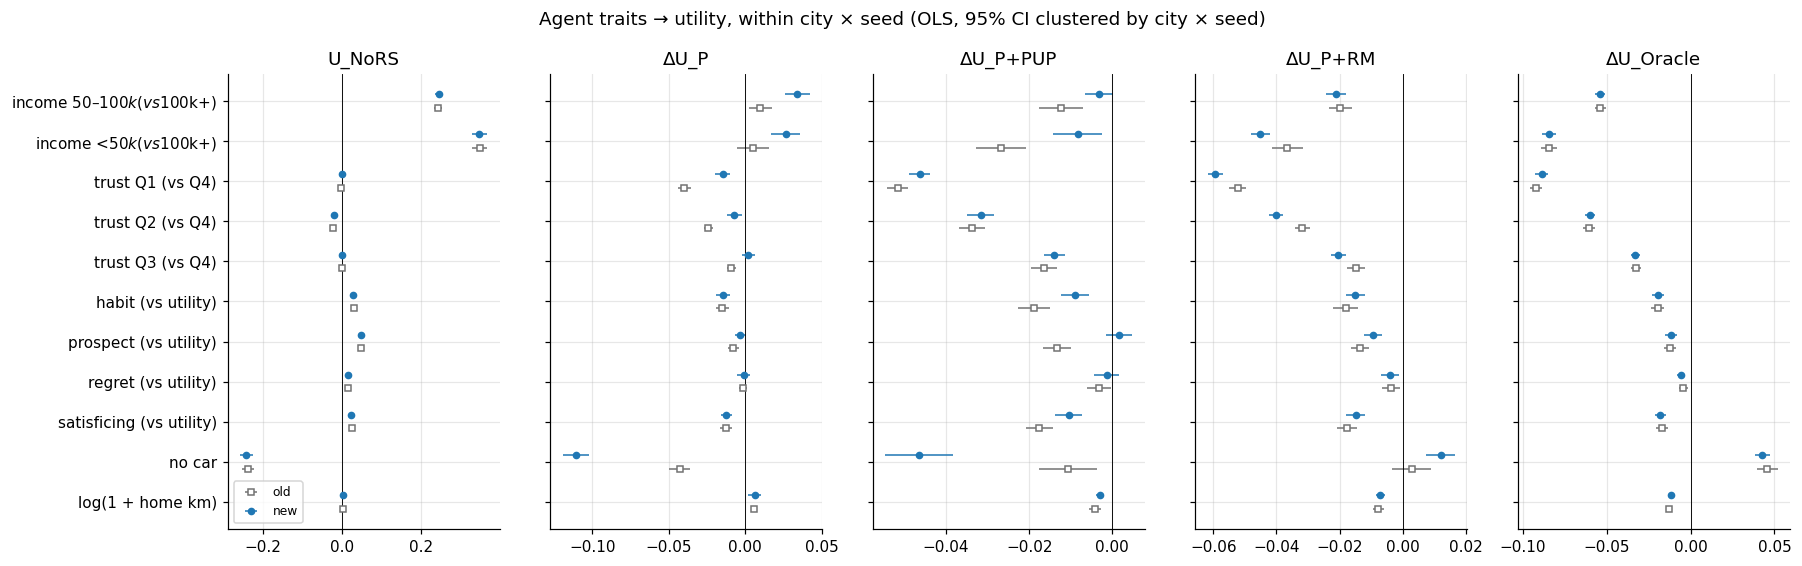

In [13]:
RHS = ("C(income3, Treatment('$100k+')) + C(trust, Treatment('Q4')) + "
       "C(paradigm, Treatment('utility')) + no_car + log_home_km + C(cs)")
NICE = {"C(income3, Treatment('$100k+'))[T.$50–100k]": "income $50–100k (vs $100k+)",
        "C(income3, Treatment('$100k+'))[T.<$50k]": "income <$50k (vs $100k+)",
        "C(trust, Treatment('Q4'))[T.Q1]": "trust Q1 (vs Q4)", "C(trust, Treatment('Q4'))[T.Q2]": "trust Q2 (vs Q4)",
        "C(trust, Treatment('Q4'))[T.Q3]": "trust Q3 (vs Q4)",
        "C(paradigm, Treatment('utility'))[T.habit]": "habit (vs utility)",
        "C(paradigm, Treatment('utility'))[T.prospect]": "prospect (vs utility)",
        "C(paradigm, Treatment('utility'))[T.regret]": "regret (vs utility)",
        "C(paradigm, Treatment('utility'))[T.satisficing]": "satisficing (vs utility)",
        "no_car": "no car", "log_home_km": "log(1 + home km)"}

def fe_ols(f, y):
    f = f.dropna(subset=[y])
    m = smf.ols(f"Q('{y}') ~ {RHS}", data=f).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(f.cs)[0]})
    b = m.params[[k for k in NICE if k in m.params]]
    se = m.bse[b.index]
    # within-R²: share of within-environment variance explained by agent traits
    y_w = f[y] - f.groupby("cs")[y].transform("mean")
    r2w = 1 - (m.resid ** 2).sum() / (y_w ** 2).sum()
    return pd.DataFrame({"b": b, "lo": b - 1.96 * se, "hi": b + 1.96 * se, "p": m.pvalues[b.index]}).rename(NICE), r2w

REG = {}
for r in ("new", "old"):
    for y in [o for o in OUTCOME_CONDS if o in AF[r].columns]:
        REG[(r, y)] = fe_ols(AF[r], y)
coef = pd.concat({k: v[0] for k, v in REG.items()}, names=["run", "outcome"])
fmt = (coef.b.map("{:+.3f}".format) + np.where(coef.p < .001, "***", np.where(coef.p < .01, "**", np.where(coef.p < .05, "*", ""))))
tab = fmt.unstack(["run", "outcome"])
tab.loc["within-R²"] = [f"{REG[k][1]:.3f}" for k in tab.columns]
display(tab["new"]); display(tab["old"])

# Sensitivity: coefficients old vs new (95% cluster-robust CIs)
SH = [o for o in OUTCOME_CONDS if o in AF["old"].columns]
terms = list(NICE.values())
fig, axs = plt.subplots(1, len(SH), figsize=(3.3 * len(SH), 5.2), sharey=True)
for ax, y in zip(axs, SH):
    for r, dy, mk in [("old", .17, "s"), ("new", -.17, "o")]:
        c = REG[(r, y)][0].reindex(terms)
        yy = np.arange(len(terms)) + dy
        ax.errorbar(c.b, yy, xerr=[c.b - c.lo, c.hi - c.b], fmt=mk, ms=4, lw=1,
                    color="C0" if r == "new" else "0.45", mfc="C0" if r == "new" else "white", label=r)
    ax.axvline(0, color="k", lw=.6); ax.set_title(y); ax.invert_yaxis() if y == SH[0] else None
axs[0].set_yticks(range(len(terms)), terms); axs[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Agent traits → utility, within city × seed (OLS, 95% CI clustered by city × seed)")
fig.tight_layout(); fig.savefig(FIG / "agent_trait_coefficients_old_vs_new.png", bbox_inches="tight")

# How the car-free gap varies by city (raw means, paired agents)
cg = pd.concat({r: AFp[r].groupby(["city", "car_access"])[["U_NoRS", "ΔU_P", "ΔU_P+RM"]].mean().unstack()
                for r in ("old", "new")}, axis=1)
cg[("new", "car-free share", "")] = AFp["new"].groupby("city").no_car.mean()
display(cg.round(3))

## 3. Latent class analysis: recommender-response personas

Following Ng, Mishra & Chen (2025), a two-step LCA with mixed indicators: classes are enumerated on **indicators only** (their Table 2 and Fig. 3), the chosen K is profiled (Tables 3 and 5, Fig. 4), and **covariates** then predict class membership through a multinomial logit (Table 4).
The covariate step here uses modal class assignment (an uncorrected three-step approach), which is fine when entropy is high (> 0.8).

**Unit:** an agent × seed in the **new** run (8 cities × 5 seeds × 2,000), using the agent's utility averaged over all 100 days.

| indicator | type | meaning |
|---|---|---|
| Baseline utility | continuous | avg utility under No RS |
| Personalized gain | continuous | U(P) − U(No RS), same agent and seed |
| PUP gain | continuous | U(P+PUP) − U(No RS) |
| RM gain | continuous | U(P+RM) − U(No RS) |
| Oracle headroom | continuous | U(Oracle) − U(No RS) |
| Acceptance | binary | took a recommendation on the last day under Personalized (missing if no trip; handled by FIML) |

P+PUP+RM gain is left out: it correlates 0.82–0.83 with PUP and RM gains, which would break local independence and add spurious classes.
Continuous indicators are winsorized at the 0.5 / 99.5 percentiles and z-scored before fitting. Class means are reported on the raw scale.

**Caveats (read before interpreting classes):**
- *Shared baseline:* every gain is U(c) − U(No RS), so the baseline enters all four gains with a minus sign. Noise in an agent's baseline therefore induces negative baseline–gain correlation (regression to the mean). Part of the "low baseline, high headroom" pattern is mechanical. Averaging over 100 days limits this but does not remove it.
- *Local independence:* the gains stay correlated within classes. This, together with n ≈ 79k, is why the information criteria never reach a minimum.
- *Acceptance* is one last-day binary per agent, missing for ~43% of agents (no last-day trip). Skipping missing values is valid under MAR.
- *Covariate step:* modal assignment attenuates odds ratios toward 1 when entropy < 1 (here ≈ 0.85). With n ≈ 79k almost every OR is "significant", so read effect sizes, not stars. Agents within a city × seed share an environment, so SEs are clustered by city × seed (40 clusters). City dummies vary only between clusters, so their p-values are the least reliable.
- The paper's LMR test is not implemented. K is chosen on IC elbow, entropy, class size and interpretability.

**Covariates:** income (3 harmonized bands), trust quartile, decision paradigm, car access, city, and log distance from home to downtown.

In [14]:
A = agents["new"]
key = ["city", "seed", "agent_id"]
Uw = A.pivot_table(index=key, columns="condition", values="avg_utility_all_days")
Tw = A.pivot_table(index=key, columns="condition", values="took_recommendation_last_day")

IND_CONT = {"Baseline utility": Uw["No RS"],
            "Personalized gain": Uw["Personalized"] - Uw["No RS"],
            "PUP gain": Uw["Personalized + PUP"] - Uw["No RS"],
            "RM gain": Uw["Personalized + RM"] - Uw["No RS"],
            "Oracle headroom": Uw["Oracle"] - Uw["No RS"]}
IND_BIN = {"Acceptance": Tw["Personalized"]}
X = pd.DataFrame({**IND_CONT, **IND_BIN}).dropna(subset=list(IND_CONT))
print(f"agents × seeds with a leisure trip under every condition: {len(X):,}")

def prep(X, cont):
    Z = X[cont].clip(X[cont].quantile(.005), X[cont].quantile(.995), axis=1)
    return ((Z - Z.mean()) / Z.std()).values

Zc, Zb = prep(X, list(IND_CONT)), X[list(IND_BIN)].values
display(X.corr().round(2))

agents × seeds with a leisure trip under every condition: 79,051


,Baseline utility,Personalized gain,PUP gain,RM gain,Oracle headroom,Acceptance
Baseline utility,1.00,0.14,-0.07,-0.28,-0.50,-0.01
Personalized gain,0.14,1.00,0.50,0.42,0.21,0.06
PUP gain,-0.07,0.50,1.00,0.71,0.53,0.11
RM gain,-0.28,0.42,0.71,1.00,0.76,0.14
Oracle headroom,-0.50,0.21,0.53,0.76,1.00,0.16
Acceptance,-0.01,0.06,0.11,0.14,0.16,1.00


,Log-likelihood,AIC,BIC,SABIC,Entropy,LL replicated,Class shares (%)
k,,,,,,,
1,-591321.447,1182664.894,1182766.950,1182731.992,NaN,True,100
2,-501968.073,1003982.146,1004195.537,1004122.442,0.827,True,"58, 42"
3,-461250.963,922571.925,922896.650,922785.419,0.848,True,"38, 34, 28"
4,-440573.794,881241.588,881677.647,881528.280,0.853,True,"33, 25, 22, 20"
5,-424322.436,848762.871,849310.264,849122.761,0.861,True,"30, 24, 19, 16, 11"
6,-414403.273,828948.546,829607.273,829381.633,0.860,True,"24, 24, 17, 15, 13, 8"


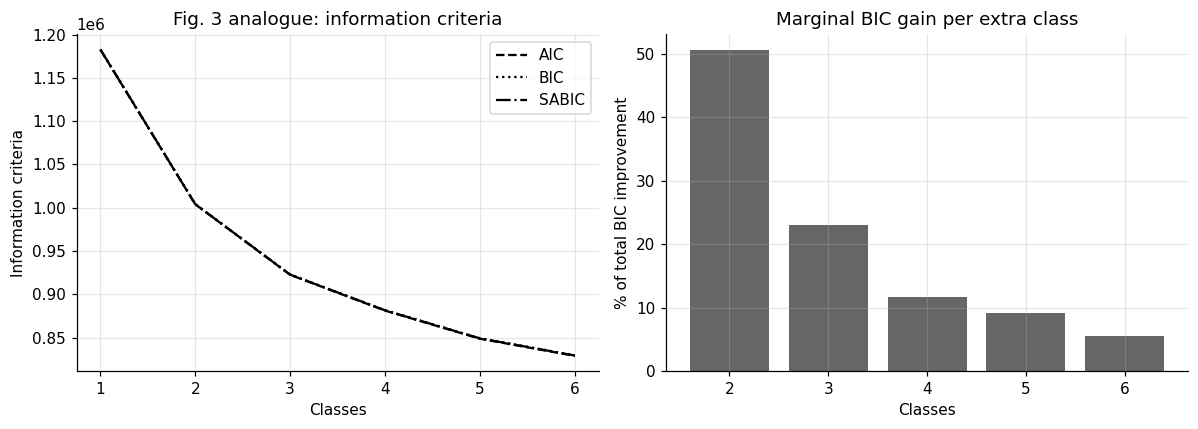

In [15]:
enum = {}
for k in range(1, 7):
    enum[k] = fit_lca(Zc, Zb, k, n_starts=LCA_STARTS, seed=k)
t2 = pd.DataFrame([{"k": k, "Log-likelihood": r.loglik, "AIC": r.aic, "BIC": r.bic, "SABIC": r.sabic,
                    "Entropy": r.entropy, "LL replicated": r.replicated,
                    "Class shares (%)": ", ".join(f"{100 * w:.0f}" for w in r.weights)} for k, r in enum.items()]).set_index("k")
display(t2.round(3))   # Table 2 analogue

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for crit, ls in [("AIC", "--"), ("BIC", ":"), ("SABIC", "-.")]:
    axs[0].plot(t2.index, t2[crit], ls=ls, color="k", label=crit)
axs[0].set(xlabel="Classes", ylabel="Information criteria", title="Fig. 3 analogue: information criteria"); axs[0].legend()
# BIC drops with K at n ≈ 79k; the size of each step shows where the elbow is
dB = -t2.BIC.diff()
axs[1].bar(dB.index[1:], 100 * dB[1:] / dB[1:].sum(), color="0.4")
axs[1].set(xlabel="Classes", ylabel="% of total BIC improvement", title="Marginal BIC gain per extra class")
fig.tight_layout(); fig.savefig(FIG / "lca_information_criteria.png", bbox_inches="tight")

As in the paper, the information criteria keep falling with K (n is large), so K is chosen on the elbow, entropy, smallest-class size (≥ ~5%) and interpretability. `N_CLASSES` at the top sets it, default **4**.
**If you change `N_CLASSES` or the indicators, update `CLASS_NAMES` below.** Names are assigned from the class profile, and classes are ordered largest first.

In [16]:
lc = enum[N_CLASSES]
X["class"] = lc.modal
K = N_CLASSES

# Table 3 analogue: class means on the raw indicator scale
raw = X[list(IND_CONT) + list(IND_BIN)]
t3 = raw.groupby(X["class"]).mean().T
t3.loc["n"] = X["class"].value_counts().sort_index()
t3.loc["share (%)"] = 100 * lc.weights
t3.loc["avg posterior"] = [lc.posterior[X["class"] == k, k].mean() for k in range(K)]
t3.loc["harmed by P (%)"] = 100 * (X["Personalized gain"] < 0).groupby(X["class"]).mean()
t3.loc["harmed by P+RM (%)"] = 100 * (X["RM gain"] < 0).groupby(X["class"]).mean()
t3.round(3)

class,0,1,2,3
Baseline utility,0.207,0.302,-0.191,0.052
Personalized gain,0.075,0.032,-0.078,0.124
PUP gain,0.115,0.055,0.084,0.196
RM gain,0.139,0.074,0.162,0.222
Oracle headroom,0.195,0.119,0.281,0.290
Acceptance,0.604,0.470,0.611,0.680
n,26602.000,19768.000,16966.000,15715.000
share (%),33.158,24.936,22.025,19.882
avg posterior,0.904,0.929,0.942,0.903
harmed by P (%),9.063,16.380,56.036,7.821


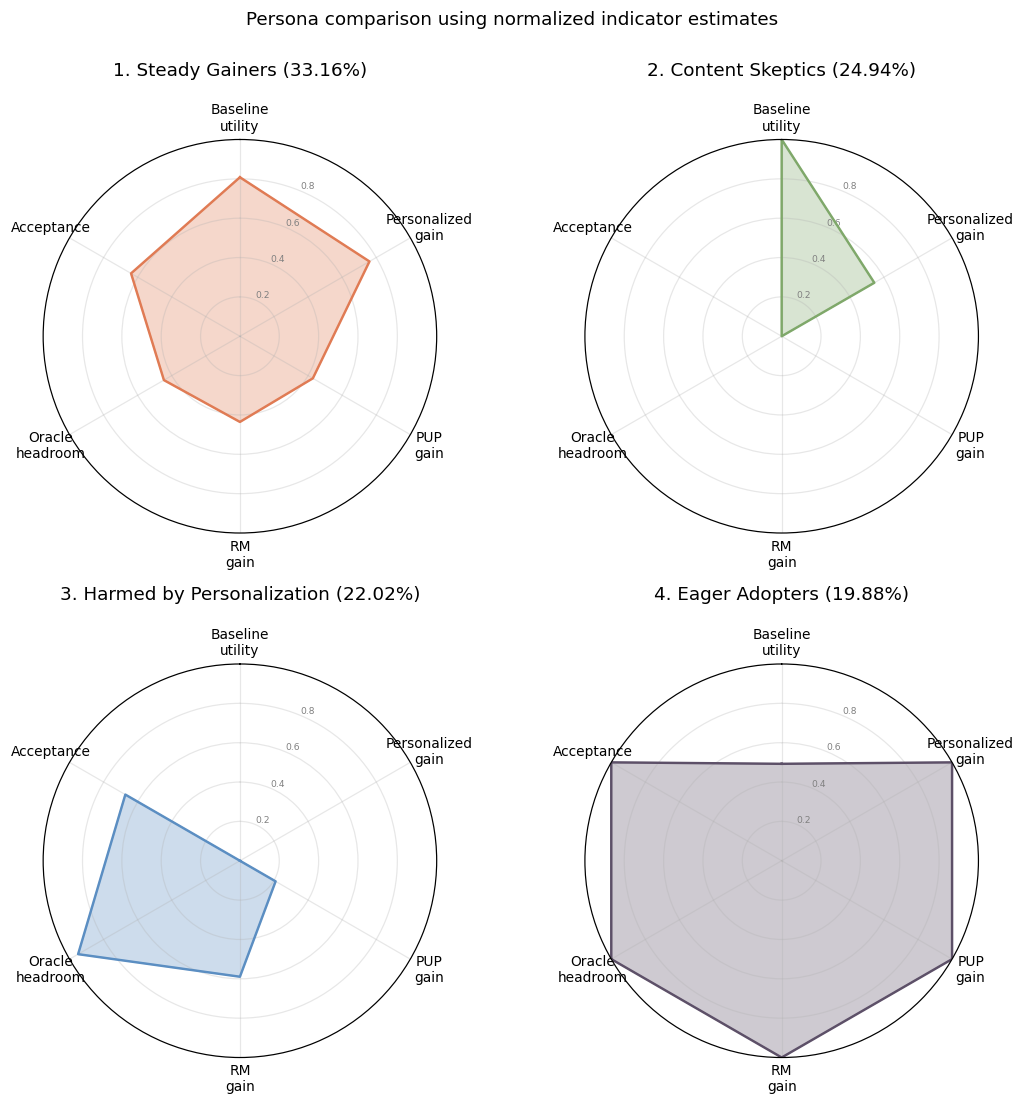

In [17]:
# Names read off t3 / t5 for the default fit (new run, K=4, seed=K). Edit if you refit.
#   1 Steady Gainers   - mid baseline, moderate gains everywhere, few harmed
#   2 Content Skeptics - best baseline, smallest gains, lowest acceptance; low trust, lower income
#   3 Harmed by Personalization - negative baseline, ~56% harmed by plain Personalized, rescued by RM;
#                      over-represents car-free agents (~40% vs 6-8% elsewhere) and NYC
#   4 Eager Adopters   - low baseline, largest gains and highest acceptance; high trust, high income
CLASS_NAMES = {0: "Steady Gainers", 1: "Content Skeptics", 2: "Harmed by Personalization", 3: "Eager Adopters"}
LABEL = {k: f"{k + 1}. {CLASS_NAMES.get(k, f'Class {k + 1}')} ({100 * lc.weights[k]:.2f}%)" for k in range(K)}
PCOL = ["#e07b54", "#7fa86a", "#5b8ec2", "#5d5068", "#c9a227", "#8c564b"]

axes_names = list(IND_CONT) + list(IND_BIN)
prof = t3.loc[axes_names].astype(float)
norm = prof.sub(prof.min(axis=1), axis=0).div((prof.max(axis=1) - prof.min(axis=1)).replace(0, 1), axis=0)   # 0..1 across classes

ncol = 2; nrow = int(np.ceil(K / ncol))
ang = np.linspace(0, 2 * np.pi, len(axes_names), endpoint=False)
fig, axs = plt.subplots(nrow, ncol, figsize=(10, 5 * nrow), subplot_kw={"projection": "polar"})
for k, ax in zip(range(K), np.ravel(axs)):
    v = norm[k].values
    ax.plot(np.r_[ang, ang[0]], np.r_[v, v[0]], color=PCOL[k], lw=1.6)
    ax.fill(np.r_[ang, ang[0]], np.r_[v, v[0]], color=PCOL[k], alpha=.3)
    ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1)
    ax.set_xticks(ang, [n.replace(" ", "\n", 1) for n in axes_names], fontsize=9)
    ax.set_ylim(0, 1); ax.set_rgrids([.2, .4, .6, .8], fontsize=6, color="0.5")
    ax.set_title(LABEL[k], pad=18, fontsize=12)
for ax in np.ravel(axs)[K:]: ax.set_visible(False)
fig.suptitle("Persona comparison using normalized indicator estimates", y=1.0); fig.tight_layout()
fig.savefig(FIG / "lca_persona_radar_grid.png", bbox_inches="tight")

### Covariates: class profiles (Table 5 analogue) and odds ratios (Table 4 analogue)

In [18]:
covA = (A[A.condition == "No RS"].set_index(key)[["income", "trust", "paradigm", "car_access", "home_lat", "home_lon"]]
        .reindex(X.index))
covA["income3"] = covA.income.map(INC)
assert covA.income3.notna().all(), covA.income[covA.income3.isna()].unique()
covA["city"] = covA.index.get_level_values("city")
covA["home_km"] = [hav_km(la, lo, *DOWNTOWN[c]) for c, la, lo in zip(covA.city, covA.home_lat, covA.home_lon)]
covA["class"] = X["class"]

t5 = {"Home distance to downtown (km)": covA.groupby("class").home_km.mean()}
for v in ["income3", "trust", "paradigm", "car_access", "city"]:
    ct = pd.crosstab(covA[v], covA["class"], normalize="columns") * 100
    for lev in ct.index: t5[f"{v}: {lev}"] = ct.loc[lev]
t5 = pd.DataFrame(t5).T; t5.columns = [LABEL[k] for k in t5.columns]
display(t5.round(2))

,1. Steady Gainers (33.16%),2. Content Skeptics (24.94%),3. Harmed by Personalization (22.02%),4. Eager Adopters (19.88%)
Home distance to downtown (km),18.14,17.54,15.52,18.71
income3: $100k+,45.47,25.86,72.88,69.18
income3: $50–100k,31.01,38.26,15.92,21.52
income3: <$50k,23.52,35.88,11.20,9.30
trust: Q1,20.55,43.79,19.64,14.73
trust: Q2,25.76,27.53,24.85,20.48
trust: Q3,29.34,17.05,24.79,28.06
trust: Q4,24.35,11.62,30.72,36.73
paradigm: habit,20.24,22.23,20.42,17.89
paradigm: prospect,20.37,19.34,16.80,20.05


In [19]:
import statsmodels.api as sm

base_k = int(np.argmax(lc.weights))   # baseline = largest class, as Lunch Breakers in the paper
D = pd.get_dummies(covA[["income3", "trust", "paradigm", "car_access", "city"]], dtype=float)
D = D.drop(columns=["income3_$100k+", "trust_Q4", "paradigm_utility", "car_access_own car", "city_nyc"])
D["log home km"] = np.log1p(covA.home_km)
y = covA["class"].values
yy = np.where(y == base_k, 0, np.where(y < base_k, y + 1, y))      # put the baseline at code 0
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mn = sm.MNLogit(yy, sm.add_constant(D)).fit(disp=0, maxiter=200, cov_type="cluster",
                                               cov_kwds={"groups": pd.factorize(covA.city + "_" + covA.index.get_level_values("seed").astype(str))[0]})
others = [k for k in range(K) if k != base_k]
OR = np.exp(mn.params); P = mn.pvalues
t4 = pd.DataFrame({f"{LABEL[k]} vs {CLASS_NAMES.get(base_k, base_k)}":
                   OR.iloc[:, i].map("{:.2f}".format) + np.where(P.iloc[:, i] < .05, "*", "")
                   for i, k in enumerate(others)}).drop("const")
print("Odds ratios; baselines: income $100k+, trust Q4, paradigm utility, own car, city NYC. * p < .05 (SEs clustered by city × seed)")
t4

Odds ratios; baselines: income $100k+, trust Q4, paradigm utility, own car, city NYC. * p < .05 (SEs clustered by city × seed)


,2. Content Skeptics (24.94%) vs Steady Gainers,3. Harmed by Personalization (22.02%) vs Steady Gainers,4. Eager Adopters (19.88%) vs Steady Gainers
income3_$50–100k,2.43*,0.11*,0.41*
income3_<$50k,3.18*,0.05*,0.21*
trust_Q1,5.13*,0.51*,0.40*
trust_Q2,2.40*,0.59*,0.48*
trust_Q3,1.25*,0.56*,0.61*
paradigm_habit,1.25*,0.83*,0.76*
paradigm_prospect,1.10*,0.60*,0.83*
paradigm_regret,1.06,0.81*,0.95
paradigm_satisficing,1.25*,0.84*,0.82*
car_access_none,0.91,43.17*,1.88*


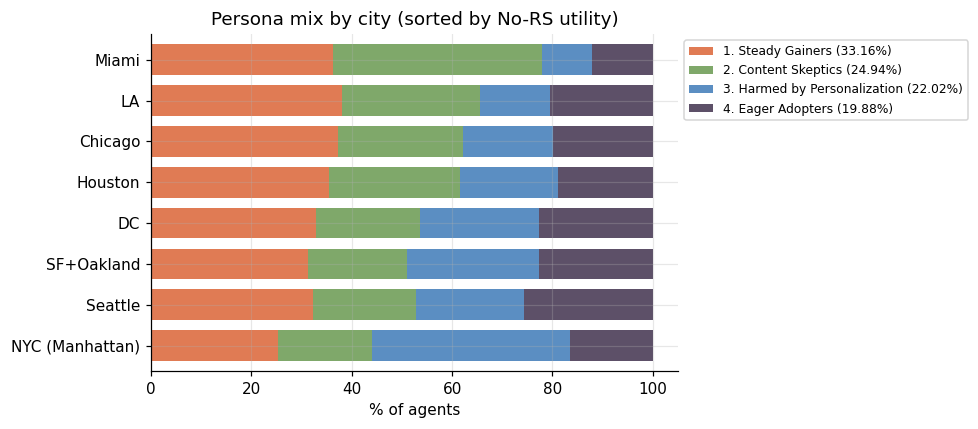

In [20]:
sh = pd.crosstab(covA.city, covA["class"], normalize="index") * 100
sh.columns = [LABEL[k] for k in sh.columns]
sh = sh.loc[OUT["new"].sort_values("U_NoRS").index]
ax = sh.plot.barh(stacked=True, color=PCOL[:K], figsize=(9, 4), width=.75)
ax.set(xlabel="% of agents", ylabel="", title="Persona mix by city (sorted by No-RS utility)")
ax.legend(bbox_to_anchor=(1, 1), fontsize=8); ax.set_yticklabels([CITY_LABEL[c] for c in sh.index])
plt.tight_layout(); plt.savefig(FIG / "lca_persona_mix_by_city.png", bbox_inches="tight")

### Persona stability across runs (sensitivity)

The same K is fit separately to old and new on the **paired agents** (`agent_id < 2000`, same seed). Acceptance is dropped because the old zip has no acceptance record. Agreement is measured with the adjusted Rand index (1 = identical partitions, 0 = chance).

In [21]:
from sklearn.metrics import adjusted_rand_score
cont = list(IND_CONT)
def indicators(r):
    a = agents[r][agents[r].agent_id < 2000]
    u = a.pivot_table(index=key, columns="condition", values="avg_utility_all_days")
    return pd.DataFrame({"Baseline utility": u["No RS"], "Personalized gain": u["Personalized"] - u["No RS"],
                         "PUP gain": u["Personalized + PUP"] - u["No RS"], "RM gain": u["Personalized + RM"] - u["No RS"],
                         "Oracle headroom": u["Oracle"] - u["No RS"]}).dropna()
Io, In = indicators("old"), indicators("new")
idx = Io.index.intersection(In.index); Io, In = Io.loc[idx], In.loc[idx]
fo = fit_lca(prep(Io, cont), np.empty((len(Io), 0)), K, n_starts=LCA_STARTS, seed=1)
fn = fit_lca(prep(In, cont), np.empty((len(In), 0)), K, n_starts=LCA_STARTS, seed=1)
print(f"paired agents: {len(idx):,}   ARI(old, new) = {adjusted_rand_score(fo.modal, fn.modal):.3f}")
ct = pd.crosstab(pd.Series(fo.modal, name="old class"), pd.Series(fn.modal, name="new class"), normalize="index")
display((100 * ct).round(1))
display(pd.concat({"old": Io.groupby(fo.modal).mean().T, "new": In.groupby(fn.modal).mean().T}, axis=1).round(3))

paired agents: 78,081   ARI(old, new) = 0.198


new class,0,1,2,3
old class,,,,
0,51.0,17.6,7.9,23.6
1,34.5,54.2,6.1,5.2
2,19.0,2.4,30.8,47.8
3,5.9,5.3,79.3,9.5


old                         new                     
                       0      1      2      3      0      1      2      3
Baseline utility   0.172  0.279 -0.036 -0.209  0.213  0.304 -0.179  0.067
Personalized gain  0.127  0.041  0.225  0.036  0.074  0.031 -0.052  0.124
PUP gain           0.147  0.056  0.257  0.116  0.113  0.054  0.104  0.192
RM gain            0.141  0.052  0.251  0.132  0.137  0.073  0.181  0.217
Oracle headroom    0.212  0.124  0.325  0.286  0.193  0.118  0.295  0.283

## 4. Taste discovery

The recommender never sees an agent's latent taste. A rising taste-match rate on **accepted recommendations** means personalization is learning taste from feedback.
**Unaided** visits are the within-run control: nothing there learns, so they should stay flat. No RS shows the population baseline.
Bands are 95% intervals over the 40 city × seed runs. Days with zero recommended trips are left out rather than counted as 0.

**Caveat:** recommended visits are *accepted* offers, a selected set (agents accept when the offer beats their own pick). So the *level* of the recommended rate mixes learning with selection. The *trend* is the cleaner learning signal: the candidate pool is the same every day, and the unaided control stays flat. Oracle observes taste directly, so its rate is the ceiling.

day,1,10,30,60,100,slope (pp / 100 days)
condition,,,,,,
Personalized,0.340,0.385,0.443,0.487,0.529,16.606
Personalized + PUP,0.353,0.390,0.444,0.493,0.533,17.086
Personalized + RM,0.341,0.389,0.448,0.496,0.542,18.284
Personalized + PUP+RM,0.353,0.392,0.447,0.499,0.547,18.004
Oracle,0.814,0.826,0.828,0.826,0.827,0.428


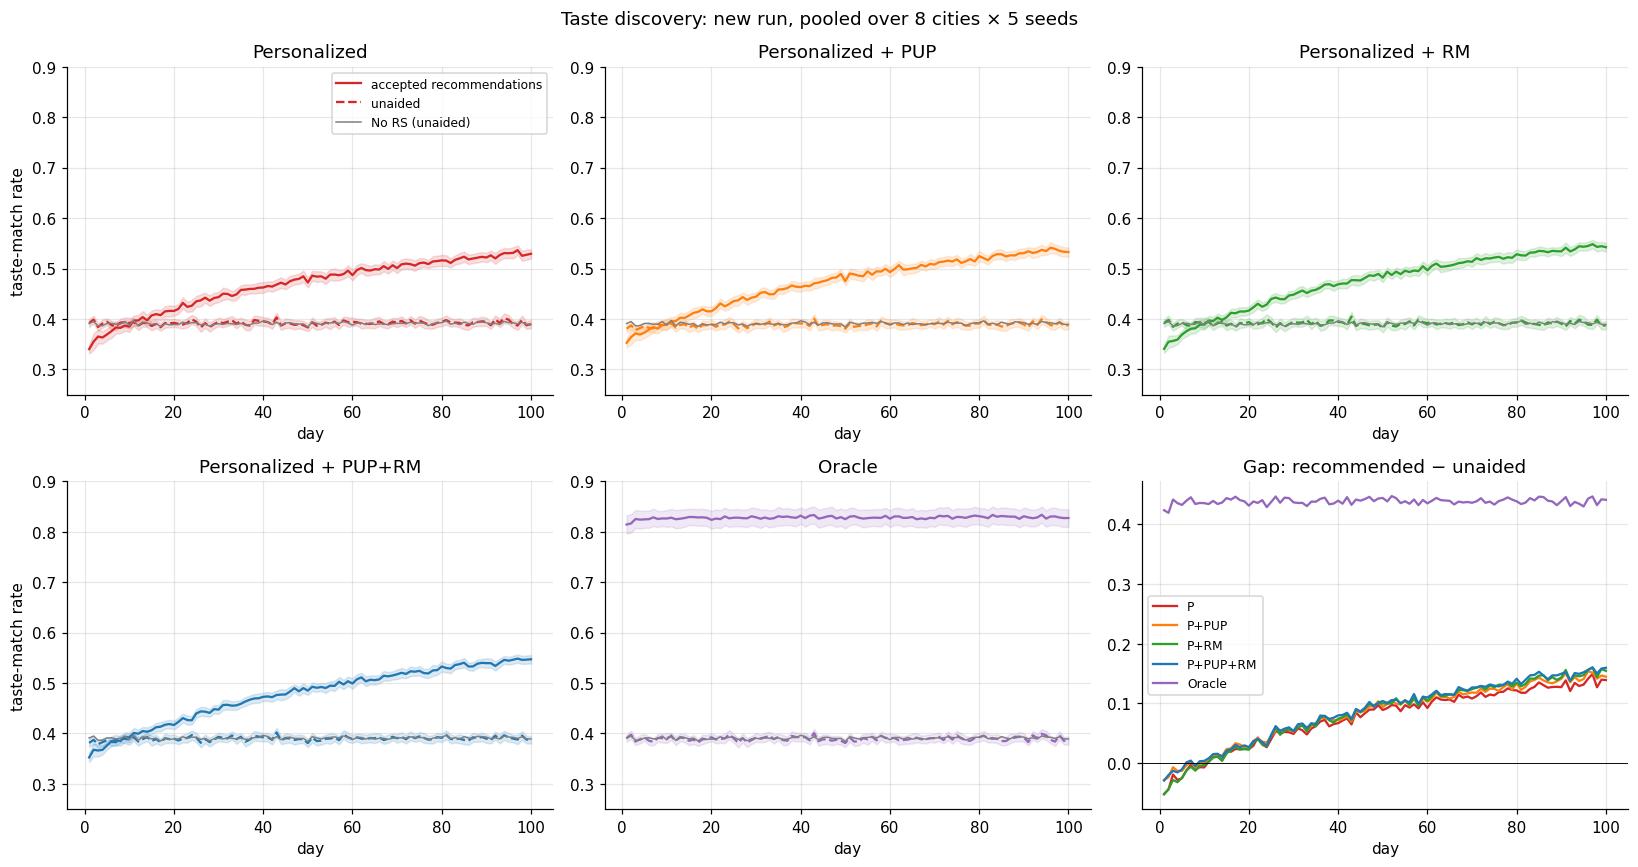

In [22]:
def prep_daily(r):
    d = daily[r].copy()
    d.loc[d.recommended_trips == 0, "taste_match_recommended"] = np.nan
    d.loc[d.organic_trips == 0, "taste_match_organic"] = np.nan
    return d
DD = {r: prep_daily(r) for r in ZIPS}

def band(d, col):
    g = d.groupby("day")[col]
    m, s, n = g.mean(), g.std(), g.count()
    return m, m - 1.96 * s / np.sqrt(n), m + 1.96 * s / np.sqrt(n)

d = DD["new"]; recs = [c for c in CONDS if c != "No RS"]
base = band(d[d.condition == "No RS"], "taste_match_organic")[0]
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axs.flat, recs):
    ax.set_ylim(.25, .9)
    for col, ls, lab in [("taste_match_recommended", "-", "accepted recommendations"), ("taste_match_organic", "--", "unaided")]:
        m, lo, hi = band(d[d.condition == c], col)
        ax.plot(m.index, m, ls=ls, color=CCOL[c], label=lab); ax.fill_between(m.index, lo, hi, color=CCOL[c], alpha=.15)
    ax.plot(base.index, base, color="0.5", lw=1, label="No RS (unaided)")
    ax.set_title(c); ax.set_xlabel("day")
axs[0, 0].set_ylabel("taste-match rate"); axs[1, 0].set_ylabel("taste-match rate"); axs[0, 0].legend(fontsize=8)
ax = axs.flat[-1]
for c in recs:
    g = d[d.condition == c].groupby("day")[["taste_match_recommended", "taste_match_organic"]].mean()
    ax.plot(g.index, g.iloc[:, 0] - g.iloc[:, 1], color=CCOL[c], label=SHORT[c])
ax.axhline(0, color="k", lw=.6); ax.set(title="Gap: recommended − unaided", xlabel="day"); ax.legend(fontsize=8)
fig.suptitle("Taste discovery: new run, pooled over 8 cities × 5 seeds"); fig.tight_layout()
fig.savefig(FIG / "taste_discovery_by_condition.png", bbox_inches="tight")

snap = (d[d.day.isin([1, 10, 30, 60, 100]) & (d.condition != "No RS")]
        .groupby(["condition", "day"]).taste_match_recommended.mean().unstack().reindex(recs))
def slope_pp_per_100d(c):
    m = d[d.condition == c].groupby("day").taste_match_recommended.mean().dropna()
    return stats.linregress(m.index, m.values).slope * 100 * 100   # per day -> per 100 days, share -> pp
snap["slope (pp / 100 days)"] = pd.Series({c: slope_pp_per_100d(c) for c in recs})
snap.round(3)

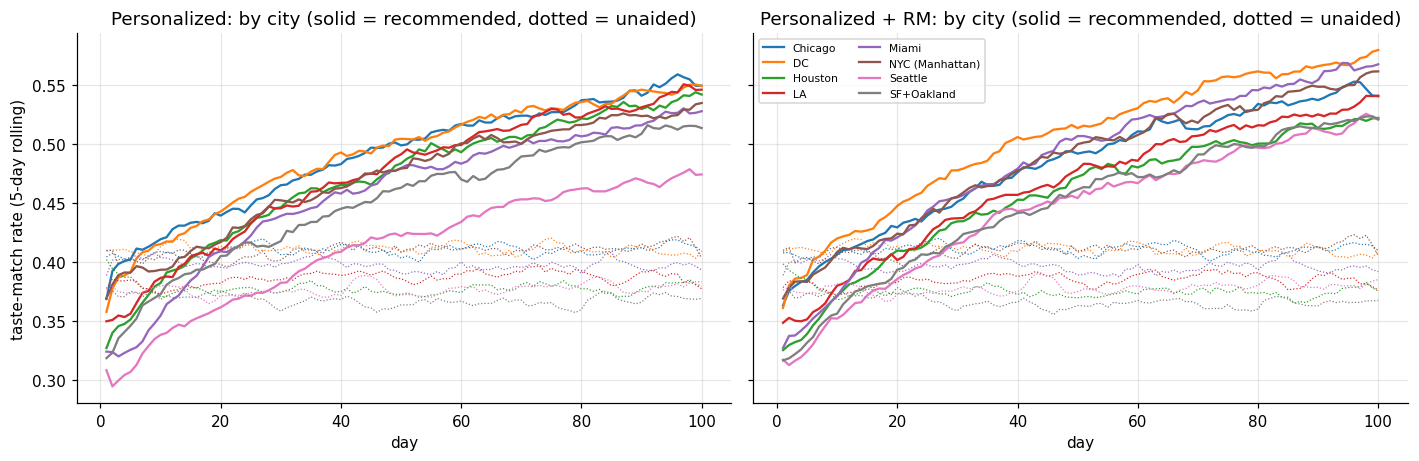

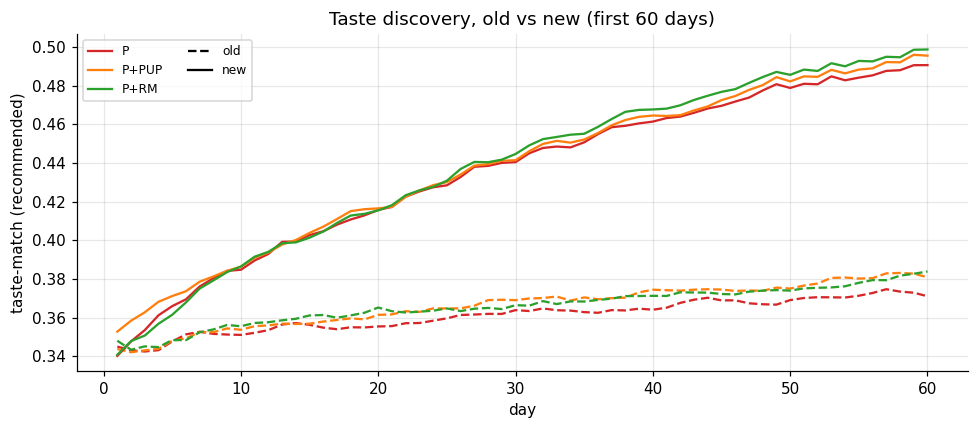

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, c in zip(axs, ["Personalized", "Personalized + RM"]):
    for i, city in enumerate(CITIES):
        g = d[(d.condition == c) & (d.city == city)].groupby("day")
        ax.plot(g.taste_match_recommended.mean().rolling(5, min_periods=1).mean(), color=f"C{i}", label=CITY_LABEL[city])
        ax.plot(g.taste_match_organic.mean().rolling(5, min_periods=1).mean(), color=f"C{i}", ls=":", lw=.8)
    ax.set(title=f"{c}: by city (solid = recommended, dotted = unaided)", xlabel="day")
axs[0].set_ylabel("taste-match rate (5-day rolling)"); axs[1].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "taste_discovery_by_city.png", bbox_inches="tight")

# old vs new over the shared 60 days
fig, ax = plt.subplots(figsize=(9, 4))
for r, ls in [("old", "--"), ("new", "-")]:
    dd = DD[r][DD[r].day <= 60]
    for c in [c for c in SHARED if c not in ("No RS", "Oracle")]:
        m = dd[dd.condition == c].groupby("day").taste_match_recommended.mean()
        ax.plot(m.index, m.rolling(3, min_periods=1).mean(), ls=ls, color=CCOL[c])
ax.legend(handles=[Line2D([], [], color=CCOL[c], label=SHORT[c]) for c in SHARED if c not in ("No RS", "Oracle")] +
          [Line2D([], [], color="k", ls="--", label="old"), Line2D([], [], color="k", label="new")], fontsize=8, ncol=2)
ax.set(xlabel="day", ylabel="taste-match (recommended)", title="Taste discovery, old vs new (first 60 days)")
fig.tight_layout(); fig.savefig(FIG / "taste_discovery_old_vs_new.png", bbox_inches="tight")

---
All figures are written to `figs/sim_analysis/`.